<div style="background:linear-gradient(135deg,#050d1a 0%,#0a1f3d 30%,#1a3a5c 65%,#2471a3 100%);padding:60px 55px;border-radius:20px;margin-bottom:28px;position:relative;overflow:hidden;box-shadow:0 20px 60px rgba(0,0,0,0.4);">
<div style="position:absolute;top:-80px;right:-80px;width:400px;height:400px;background:radial-gradient(circle,rgba(41,128,185,0.2) 0%,transparent 70%);border-radius:50%;"></div>
<div style="position:absolute;bottom:-60px;left:-40px;width:300px;height:300px;background:radial-gradient(circle,rgba(41,128,185,0.15) 0%,transparent 70%);border-radius:50%;"></div>
<div style="position:relative;z-index:1;">
<div style="color:#5dade2;font-size:12px;letter-spacing:4px;text-transform:uppercase;margin-bottom:14px;font-family:Georgia,serif;">Applied Econometrics Research</div>
<h1 style="color:#ffffff;font-family:Georgia,serif;font-size:2.3em;margin:0 0 14px 0;font-weight:700;line-height:1.25;">Three Roads to Causality: Estimating the Growth Effect of European Union Accession</h1>
<p style="color:#aed6f1;font-size:1.05em;margin:0 0 22px 0;font-family:Georgia,serif;line-height:1.6;max-width:820px;">A comparative application of Difference-in-Differences, Instrumental Variables, and Regression Discontinuity Design, framed by exploratory analysis, formal panel-data statistics, classical time series methods, and machine learning, on two decades of World Bank open data for Central, Eastern and South-Eastern Europe.</p>
<div style="color:#7fb3d5;font-size:13px;font-family:Georgia,serif;border-top:1px solid rgba(255,255,255,0.15);padding-top:14px;margin-top:10px;">Melissa Monfared</div>
</div>
</div>

<div style="background:linear-gradient(135deg,#f0f7ff 0%,#e8f4fd 50%,#f0f6ff 100%);border:1.5px solid #90caf9;border-radius:16px;padding:34px 40px;margin-bottom:26px;font-family:Georgia,serif;">
<h2 style="color:#0d47a1;margin:0 0 14px 0;font-size:1.25em;letter-spacing:1px;text-transform:uppercase;">Abstract</h2>
<div style="color:#1a3a5c;line-height:1.85;font-size:0.98em;">

Does joining the European Union make a country richer, and can we actually prove it? This notebook
uses that question as a vehicle for something broader: a full statistical research pipeline, from raw
data acquisition through exploratory analysis, formal panel-data econometrics, classical time series
methods, three causal identification strategies, and machine learning, all applied to the same
twenty-country panel.
<br><br>
We build a country-year panel for twenty European economies between 1995 and 2023 from World Bank open
data (GDP, population, and the Gini index), covering ten countries that joined the EU in 2004, two in
2007, one in 2013, and seven Western Balkan and Eastern Partnership countries that have not. After an
exploratory pass with a dozen visualisations, a formal panel-data comparison of pooled, fixed-effects,
and random-effects estimators (with a Hausman test and standard diagnostic checks) sets up the
statistical case for fixed effects, and a beta-convergence regression tests the classical growth
prediction that poorer countries grow faster. A time series pass tests for stochastic convergence with
unit-root tests, decomposes the aggregate income series, and checks for Granger causality between the
accession and comparison groups. The causal core of the notebook applies staggered
Difference-in-Differences (Callaway and Sant'Anna, 2021), an Instrumental Variables design built on
geographic distance to Brussels, and a Regression Discontinuity Design around the World Bank's
high-income classification threshold. A closing machine learning section trains a gradient boosting
model to predict income growth out of sample and fits a causal forest to recover which countries
experienced systematically larger or smaller effects of accession.
<br><br>
The point of the exercise is not to deliver a single tidy number for "the effect of the EU." It is to
show a complete, honest statistical research workflow: where each method's assumptions hold, where they
break, and how a careful analyst reports a weak instrument or a thin cluster count instead of hiding it.

</div>
</div>

<div style="background:#ffffff;border-radius:14px;padding:28px 34px;font-family:Georgia,serif;border:1.5px solid #bfdbfe;margin-bottom:26px;">
<h2 style="color:#1e40af;font-size:1.2rem;margin:0 0 16px;">Table of Contents</h2>
<div style="display:grid;grid-template-columns:1fr 1fr;gap:5px 30px;font-size:0.93rem;">
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">01 ·</span> <a href="#sec1" style="color:#1e3a8a;text-decoration:none;">Introduction and Motivation</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">02 ·</span> <a href="#sec2" style="color:#1e3a8a;text-decoration:none;">Theoretical Background</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">03 ·</span> <a href="#sec3" style="color:#1e3a8a;text-decoration:none;">Data Acquisition and Sample Construction</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">04 ·</span> <a href="#sec4" style="color:#1e3a8a;text-decoration:none;">Exploratory Data Analysis</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">05 ·</span> <a href="#sec5" style="color:#1e3a8a;text-decoration:none;">Statistical Modeling: Panel Econometrics</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">06 ·</span> <a href="#sec6" style="color:#1e3a8a;text-decoration:none;">Time Series Analysis</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">07 ·</span> <a href="#sec7" style="color:#1e3a8a;text-decoration:none;">Difference-in-Differences</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">08 ·</span> <a href="#sec8" style="color:#1e3a8a;text-decoration:none;">Instrumental Variables / 2SLS</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">09 ·</span> <a href="#sec9" style="color:#1e3a8a;text-decoration:none;">Regression Discontinuity Design</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">10 ·</span> <a href="#sec10" style="color:#1e3a8a;text-decoration:none;">Machine Learning Modeling</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">11 ·</span> <a href="#sec11" style="color:#1e3a8a;text-decoration:none;">Comparing the Estimates</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">12 ·</span> <a href="#sec12" style="color:#1e3a8a;text-decoration:none;">Limitations</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">13 ·</span> <a href="#sec13" style="color:#1e3a8a;text-decoration:none;">Conclusion</a></div>
<div style="color:#1e3a8a;padding:4px 0;"><span style="color:#93c5fd;font-weight:700;">14 ·</span> <a href="#sec14" style="color:#1e3a8a;text-decoration:none;">References</a></div>
</div>
</div>

<a id="sec1"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 1</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Introduction and Motivation</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Why EU accession, why this pipeline, and what this notebook actually tries to show</p>
</div>


Between 2004 and 2013, thirteen countries in Central, Eastern and South-Eastern Europe joined the
European Union. It is one of the largest peacetime economic integration events of the last fifty
years, and it is also, from a research design point of view, an awkward one to study.
Countries were not randomly assigned EU membership. The ones that joined first in 2004 were, on
average, the ones that had already gone furthest in market reforms, rule-of-law consolidation, and
trade liberalisation with the West during the 1990s. That means any simple comparison of EU members
against non-members is comparing two groups that were already on different trajectories before a
single accession treaty was signed. This is the selection problem, and it is the reason a course in
causal inference does not just teach you to run a regression and read off a coefficient.
<br><br>
Rather than jumping straight to causal methods, this notebook works through a complete pipeline in the
order a careful applied statistician actually would. We look at the data before we model it. We check
whether a formal panel-data test even supports the fixed-effects assumption that Difference-in-Differences
leans on. We ask whether these are well-behaved time series before treating them as one. Only then do we
turn to the three causal identification strategies: Difference-in-Differences, Instrumental Variables, and
Regression Discontinuity Design, each of which solves the selection problem in a different way, under a
different assumption, and each of which answers a subtly different version of the research question.
We close with machine learning, first as a pure prediction exercise, and then as a way to ask which
countries the EU accession effect was largest or smallest for.
<br><br>
The roadmap: Section 2 lays out the theory and identifying equations for every method used later.
Section 3 builds the panel from World Bank data, fetched live. Section 4 explores it visually. Section 5
runs formal panel econometrics and a classical convergence regression. Section 6 treats the data as time
series. Sections 7 through 9 run DiD, IV, and RDD in turn. Section 10 brings in machine learning. Section
11 puts every causal estimate side by side, and Sections 12 and 13 close with limitations and a conclusion.


<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">1.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Methods at a Glance</span>
</div>


Before the detailed derivations in Section 2, a quick-reference map of every method used, what it is
actually asking of the data, and where to find it.

<table style="width:100%;border-collapse:collapse;font-family:Georgia,serif;font-size:13px;margin:14px 0;">
<tr style="background:#0d2b4e;color:white;"><th style="padding:8px 12px;text-align:left;">Category</th><th style="padding:8px 12px;text-align:left;">Method</th><th style="padding:8px 12px;text-align:left;">What it tests or estimates</th><th style="padding:8px 12px;text-align:left;">Section</th></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;" rowspan="3"><strong>Panel econometrics</strong></td><td style="padding:7px 12px;">Pooled OLS / Fixed Effects / Random Effects + Hausman test</td><td style="padding:7px 12px;">Whether time-invariant country traits confound the naive EU-membership coefficient</td><td style="padding:7px 12px;">5.1</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;">Breusch-Pagan, Durbin-Watson, VIF</td><td style="padding:7px 12px;">Heteroskedasticity, serial correlation, and multicollinearity in the panel</td><td style="padding:7px 12px;">5.2</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;">Beta-convergence regression</td><td style="padding:7px 12px;">Whether poorer countries grow faster on average, independent of EU status</td><td style="padding:7px 12px;">5.3</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:7px 12px;" rowspan="3"><strong>Time series</strong></td><td style="padding:7px 12px;">Augmented Dickey-Fuller unit-root test</td><td style="padding:7px 12px;">Whether a country's income gap to Germany is stationary (stochastic convergence)</td><td style="padding:7px 12px;">6.1</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:7px 12px;">ARIMA</td><td style="padding:7px 12px;">Whether a purely univariate model can forecast growth out of sample</td><td style="padding:7px 12px;">6.2</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:7px 12px;">Granger causality</td><td style="padding:7px 12px;">Whether one group's growth predicts the other's with a one- or two-year lag</td><td style="padding:7px 12px;">6.3</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;" rowspan="3"><strong>Causal inference</strong></td><td style="padding:7px 12px;">Difference-in-Differences (TWFE + Callaway-Sant'Anna)</td><td style="padding:7px 12px;">The average effect of EU accession on income, robust to staggered treatment timing</td><td style="padding:7px 12px;">7</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;">Instrumental Variables / 2SLS</td><td style="padding:7px 12px;">A local average treatment effect, instrumenting accession timing with distance to Brussels</td><td style="padding:7px 12px;">8</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:7px 12px;">Regression Discontinuity Design</td><td style="padding:7px 12px;">A local effect right at the World Bank's high-income classification threshold</td><td style="padding:7px 12px;">9</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:7px 12px;" rowspan="2"><strong>Machine learning</strong></td><td style="padding:7px 12px;">Gradient boosting vs. a naive baseline</td><td style="padding:7px 12px;">Whether flexible models actually beat a simple average at predicting next-year growth</td><td style="padding:7px 12px;">10.1</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:7px 12px;">Causal forest (double machine learning)</td><td style="padding:7px 12px;">Heterogeneous EU-accession effects as a function of country characteristics</td><td style="padding:7px 12px;">10.2</td></tr>
</table>


<div style="background:#f0fdfa;border-radius:14px;padding:22px 28px;border:1.5px solid #5eead4;font-family:Georgia,serif;line-height:1.85;color:#134e4a;margin-bottom:10px;">
<h4 style="color:#0f766e;font-size:1.0rem;margin:0 0 10px;">Hypotheses</h4>

<p style="margin:0 0 10px 0;"><strong>H1 (panel structure).</strong> A Hausman test will reject the
random-effects model in favour of fixed effects, confirming that time-invariant country characteristics
are correlated with EU membership and must be swept out rather than modelled as random noise.</p>
<p style="margin:0 0 10px 0;"><strong>H2 (convergence).</strong> Poorer countries in the sample, measured
by initial GDP per capita, will show faster subsequent growth (beta-convergence), and this pattern will
be at least partly separable from any additional EU-membership effect.</p>
<p style="margin:0 0 10px 0;"><strong>H3 (DiD).</strong> Once country and year fixed effects absorb
time-invariant heterogeneity and common shocks, the estimated effect of EU accession on log GDP per
capita will shrink substantially relative to a naive correlation, and may not be statistically
distinguishable from zero in the years immediately around accession.</p>
<p style="margin:0 0 10px 0;"><strong>H4 (IV).</strong> Geographic distance from a country's capital to
Brussels predicts the timing of EU accession, conditional on initial income and population, and can be
used as an instrument for years of EU membership.</p>
<p style="margin:0 0 10px 0;"><strong>H5 (RDD).</strong> Crossing the World Bank's high-income
classification threshold is associated with a discontinuous change in income inequality.</p>
<p style="margin:0;"><strong>H6 (heterogeneity).</strong> The effect of EU accession is not constant
across countries: a causal forest will recover systematic heterogeneity correlated with observable
country characteristics such as initial income or population.</p>

</div>

<a id="sec2"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 2</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Theoretical Background</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">The identifying equations behind panel econometrics, staggered DiD, 2SLS, RDD, and causal forests</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Panel Data Models and the Selection Problem</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Consider the simplest possible regression a researcher might run: log GDP per
capita on an EU-membership indicator, pooling every country-year observation with no further structure.
Ordinary least squares recovers an unbiased effect only if membership status is uncorrelated with
everything else driving income, an assumption with a name (exogeneity) that makes it sound more
technical than it is. In plain terms it just asks: did the countries that joined the EU first differ
systematically from the ones that did not, for reasons that have nothing to do with joining the EU?
Here the answer is obviously yes. Poland, Hungary and the Baltic states were already richer, more
reform-oriented economies than Serbia or Moldova well before 2004, a legacy of how far each had gone in
market liberalisation and institutional rebuilding after 1989, not of anything the EU itself did to
them. Any regression that ignores this is not really estimating the effect of accession; it is
estimating the effect of having been the kind of country that accession-track negotiators found ready
in the first place.</p>
<p style="margin:0;">The pooled specification below makes the problem precise, and is followed by the
two standard remedies a panel gives us that a single cross-section does not.</p>

</div>

*Three panel specifications for the same outcome and regressor*


$$Y_{it} = \alpha + \beta \, D_{it} + \varepsilon_{it} \qquad \text{(pooled OLS)}$$
$$Y_{it} = \alpha_i + \beta \, D_{it} + \varepsilon_{it} \qquad \text{(fixed effects)}$$
$$Y_{it} = \alpha + \beta \, D_{it} + u_i + \varepsilon_{it}, \quad u_i \sim (0,\sigma_u^2) \text{ independent of } D_{it} \qquad \text{(random effects)}$$


<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">In the pooled model, &epsilon;<sub>it</sub> has to absorb every
country-specific trait going into income: institutional quality, geography, thirty years of reform
history, all of it. If any of that is correlated with EU membership, which we have just argued it is,
the estimate of &beta; inherits the bias. The fixed-effects model sidesteps the problem by giving every
country its own intercept, so &beta; is identified purely from movements within a country over time:
Poland's income in years when it was an EU member compared with Poland's income in years when it was
not, not Poland compared with Serbia. Any trait that is fixed over the sample period, however important,
drops out of the comparison entirely. The random-effects model is more statistically efficient, since it
uses both the within-country variation fixed effects relies on and the between-country variation it
throws away, but efficiency here comes at the price of assuming the country-specific term is uncorrelated
with membership status, the assumption Section 1 already gave us reason to distrust.</p>
<p style="margin:0;">The <strong>Hausman (1978)</strong> test turns that suspicion into a number, by
comparing the fixed-effects and random-effects coefficient vectors directly. Both estimators are
consistent if the random-effects assumption holds, so under the null they should land close together;
a large, appropriately standardised gap between them is evidence that the assumption has failed and
random effects should be abandoned in favour of fixed effects. (Section 10 revisits this same tension
in a machine-learning setting, adding country-level averages as controls, a device that goes back to
Mundlak (1978), as a way of approximating what a fixed effect buys us without literally demeaning the
data.)</p>

</div>

$$H = (\hat\beta_{FE} - \hat\beta_{RE})' \big[Var(\hat\beta_{FE}) - Var(\hat\beta_{RE})\big]^{-1} (\hat\beta_{FE} - \hat\beta_{RE}) \ \sim \ \chi^2_k \text{ under } H_0$$

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Beta-Convergence</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Set the EU question aside for a moment. Neoclassical growth theory makes
an unconditional prediction that has nothing to do with policy at all: economies with less capital per
worker should see higher returns to additional investment, and should therefore grow faster, purely as
a matter of diminishing returns. Barro and Sala-i-Martin (1992) gave this prediction its now-standard
empirical test and its name, <strong>beta-convergence</strong>: regress each economy's subsequent growth
rate on its initial income level and check whether the slope is negative.</p>

</div>

$$\frac{1}{T}\ln\!\left(\frac{Y_{i,t_0+T}}{Y_{i,t_0}}\right) = a + b \, \ln(Y_{i,t_0}) + \eta_i$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">A negative and significant slope <em>b</em> says countries that started poorer in year
t<sub>0</sub> grew faster on average over the following years, just what the theory predicts if nothing else
is going on. Note the hedge: this is <em>unconditional</em> convergence, with no controls for savings
rates, education, or institutional quality, the things a fuller Solow-style specification would include
and that the later convergence literature spent a great deal of effort arguing over. We use it here in
its simplest form deliberately, as a baseline check rather than a structural growth model.</p>
<p style="margin:0;">The result matters for reading the causal sections that follow for a specific
reason: if convergence is operating across the whole sample regardless of EU status, part of what a
naive Difference-in-Differences design might attribute to accession could really be ordinary catch-up
growth that a poorer country would have experienced with or without a treaty in Brussels.</p>

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Time Series: Stochastic Convergence, Decomposition, and Granger Causality</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Beta-convergence is a claim about a single cross-section, one growth rate
per country over one long window. A time series analogue asks a sharper question: is the income gap
between a given country and a stable benchmark economy actually <em>mean-reverting</em> year by year, or
does it just happen to look smaller after enough time has passed? Carlino and Mills (1993) formalised
this as <strong>stochastic convergence</strong>, tested with an Augmented Dickey-Fuller (ADF) unit-root
test on the gap series itself, the log income difference between a country and the benchmark:</p>

</div>

$$\Delta g_{it} = \rho \, g_{i,t-1} + \sum_{j=1}^{p} \phi_j \, \Delta g_{i,t-j} + \epsilon_{it}$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">The null hypothesis is that the gap contains a unit root, meaning shocks to
it never fade and it is free to wander arbitrarily far in either direction; rejecting the null in favour
of a negative reversion coefficient &rho; is evidence that the gap is instead pulled back toward some
long-run level whenever it strays. This is a strictly stronger requirement than beta-convergence, and,
as Section 6.1 shows, one that not every country in this sample actually satisfies.</p>
<p style="margin:0;">Granger (1969) causality asks a different question again, and a purely predictive
one: does the past of one series help forecast another series, beyond what that series' own past already
tells you? Granger himself was careful to note that this is a statement about forecasting, not about
mechanism, a caution that got lost somewhere between the original paper and the name everyone actually
uses for the test.</p>

</div>

$$Y_t = c + \sum_{j=1}^{p}\alpha_j Y_{t-j} + \sum_{j=1}^{p}\beta_j X_{t-j} + u_t, \qquad H_0: \beta_1=\cdots=\beta_p=0$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0;">Rejecting the null means past values of <em>X</em> improve a forecast of <em>Y</em> built from
<em>Y</em>'s own history alone. That is useful information on its own terms, but it is not a causal claim, which is
why Section 6.3 uses it only as a descriptive check for shared shocks and spillovers between the
accession and comparison groups, not as a fourth identification strategy alongside DiD, IV and RDD.</p>

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.4</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Difference-in-Differences and Staggered Treatment Timing</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Return now to the actual research question. The classic two-period,
two-group DiD estimator compares the change in outcomes for a treated group against the change for a
control group over the same window. Subtracting away each group's own before-after difference removes
any time-invariant level gap between the groups (the same gap that sank the naive regression in Section
2.1), and comparing that difference to the control group's own change removes anything happening to
both groups at once, a shared recession or a shared boom. What remains, under the assumption that the
two groups would have moved in parallel absent treatment, is attributable to the treatment itself.</p>

</div>

$$\hat\tau_{DID} = \big(\bar Y_{treat,\,post} - \bar Y_{treat,\,pre}\big) - \big(\bar Y_{control,\,post} - \bar Y_{control,\,pre}\big)$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">That parallel-trends assumption is doing all the identifying work and is
never directly testable, since it is a statement about what would have happened, not what did. The
closest we can get is checking that trends looked parallel <em>before</em> treatment and hoping nothing
changes that logic afterward, which is what the pre-period of the event study in Section 7.2
is for. In a panel with many periods, the two-group estimator above is usually implemented as the
two-way fixed-effects (TWFE) regression from Section 2.1, with the regressor now specifically an
EU-membership indicator. EU accession did not happen all at once, though: ten countries joined in 2004,
two in 2007, and one in 2013, which makes this a <strong>staggered adoption</strong> design, and staggered
designs turn out to break TWFE in a way that took the econometrics literature until surprisingly
recently to fully appreciate. Goodman-Bacon (2021) showed that the single TWFE coefficient in this
setting is a weighted average of every possible pairwise 2x2 DiD comparison hiding inside the data,
including comparisons where an early-treated cohort is used, implicitly and incorrectly, as a control
group for a cohort that has not yet been treated. Some of those implicit comparison weights can be
negative, and if the true treatment effect changes over time, which is precisely what we would expect if
EU accession's growth dividend fades or evolves with years of membership, the single TWFE number can end
up biased, or even carry the wrong sign, relative to any sensible average of the true cohort-specific
effects.</p>

</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Callaway and Sant'Anna (2021) fix this not by patching the regression but
by refusing to run one aggregate regression in the first place. Instead they build the estimator up from
a large collection of well-defined 2x2 comparisons. For a cohort <em>g</em> (the calendar year in which a group
of countries first becomes treated) and a later period <em>t</em>, the group-time average treatment effect is
defined directly from potential outcomes:</p>

</div>


$$ATT(g,t) = E\big[Y_t(g) - Y_t(0) \mid G_g = 1\big]$$
$$\widehat{ATT}(g,t) = \Big(E[Y_t - Y_{g-1} \mid G_g = 1]\Big) - \Big(E[Y_t - Y_{g-1} \mid C = 1]\Big), \qquad t \geq g-1$$


<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">where <em>C</em> denotes the never-treated comparison group, which in this
notebook is the set of Western Balkan and Eastern Partnership countries that never joined at all. Every
single ATT(g,t) only ever compares a cohort to units that are not yet treated at time <em>t</em>, so the
Goodman-Bacon problem of an already-treated cohort quietly serving as a bad control simply cannot arise
by construction. These many small building blocks are then aggregated back up in two ways that answer
two different questions: an event-study aggregation groups them by event time (years since accession) to
trace out a dynamic effect, and a simple aggregation collapses everything into one overall post-treatment
average, weighted by cohort size, for a single headline number.</p>

</div>


$$\theta_{es}(e) = \sum_{g} \Pr(G=g \mid G+e \le T) \cdot ATT(g,\,g+e) \qquad \theta_{simple} = \sum_{g} \Pr(G=g) \cdot \frac{1}{|\{t \ge g\}|}\sum_{t \ge g} ATT(g,t)$$


<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.5</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Instrumental Variables and Two-Stage Least Squares</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">DiD handles selection on time-invariant traits by differencing them away.
Instrumental variables handles a subtler version of the same problem, where the regressor of interest is
itself entangled with the error term in a way that no amount of differencing fixes. Suppose we want the
effect of an endogenous regressor D<sub>i</sub>, years of EU membership, on an outcome Y<sub>i</sub>, cumulative income
growth, and suppose D<sub>i</sub> is correlated with u<sub>i</sub>:</p>

</div>

$$Y_i = \beta_0 + \beta_1 D_i + \beta_2 X_i + u_i, \qquad Cov(D_i, u_i) \neq 0$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">An instrument Z<sub>i</sub> rescues identification if it satisfies two conditions,
one of which we can check and one of which we cannot. Relevance requires Z<sub>i</sub> to be correlated with
D<sub>i</sub> after conditioning on X<sub>i</sub>, and is tested directly in the first-stage regression below; this is
an empirical question with a definite answer. The exclusion restriction requires Z<sub>i</sub> to affect Y<sub>i</sub>
only through its effect on D<sub>i</sub>, and has no such test: it can only be argued for, using knowledge of
the setting that no regression can supply on its own. Geography, our candidate instrument here, is the
kind of variable applied researchers reach for precisely because it is plausibly exogenous to modern
economic outcomes, though as Section 8 shows, plausible is not the same as sufficient.</p>

</div>


$$D_i = \pi_0 + \pi_1 Z_i + \pi_2 X_i + v_i \qquad \text{(first stage, relevance: } \pi_1 \neq 0 \text{)}$$
$$Y_i = \beta_0 + \beta_1 \hat D_i + \beta_2 X_i + \varepsilon_i \qquad \text{(second stage)}$$
$$\hat\beta_1^{IV} = \frac{Cov(Y_i,\,Z_i)}{Cov(D_i,\,Z_i)} \qquad \text{(just-identified Wald estimator)}$$


<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0;">A weak first stage, meaning the coefficient on the instrument is close to zero or too imprecisely estimated
to tell, is not a cosmetic problem to be noted in a footnote and moved past. When the first-stage
F-statistic on the excluded instrument falls well below the conventional rule-of-thumb of 10 (Stock and
Yogo, 2005), the 2SLS estimator's own sampling distribution stops being well approximated by the usual
normal theory, which means the point estimate, its standard error, and any confidence interval built
from it are all simultaneously unreliable, not just noisy. Section 8 walks through this same
situation, F-statistic and all, rather than quietly reporting the second-stage coefficient as though
nothing were wrong with the first.</p>

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.6</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Regression Discontinuity Design</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Where DiD leans on parallel trends and IV leans on an argued-for exclusion
restriction, RDD leans on something closer to a bureaucratic accident: a sharp, arbitrary administrative
rule that assigns treatment purely on which side of a threshold a running variable happens to fall.</p>

</div>


$$D_i = \mathbb{1}\{X_i \ge c\}, \qquad Y_i = \alpha + \tau D_i + f(X_i - c) + \varepsilon_i$$
$$\hat\tau_{RD} = \hat m_{+}(c) - \hat m_{-}(c)$$


<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Identification rests on continuity: the conditional expectation of each
potential outcome is continuous in the running variable at the cutoff, so units just above and just
below the cutoff are, in the limit as the bandwidth shrinks, comparable in every way except treatment status. A
government can, and often does, manipulate policy generally; what it usually cannot do is finely control
which side of an arbitrary numerical line a country lands on in a given year, which is what
makes the design credible when it applies at all.</p>
<p style="margin:0;">We use the bias-corrected, robust local-linear estimator of Calonico, Cattaneo and
Titiunik (2014), which fits weighted local-linear regressions within a data-driven bandwidth on each
side of the cutoff using a triangular kernel (more weight to observations closer to the threshold), then
applies a bias correction based on a local-quadratic fit before computing standard errors that account
for this correction. This is what the <code>rdrobust</code> package implements directly, and what
Section 9 reports without needing to hand-roll the estimator ourselves.</p>

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">2.7</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Causal Forests and Heterogeneous Treatment Effects</span>
</div>

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0 0 14px 0;">Every method up to this point returns one number: an average effect
across countries, or around a cutoff. That average can hide as much as it reveals if the true effect
differs meaningfully across units, which the beta-convergence result in Section 2.2 already gives us
reason to suspect might be true here. Athey and Imbens (2016) proposed recovering that heterogeneity
directly by partitioning the covariate space into subgroups that differ in treatment effect, an idea
Wager and Athey (2018) and Athey, Tibshirani and Wager (2019) generalised into the <strong>causal
forest</strong>: an ensemble of trees, each grown not to minimise prediction error the way an ordinary
regression tree does, but to maximise heterogeneity in the estimated treatment effect between the leaves
it produces.</p>

</div>

$$\tau(x) = E\big[Y_i(1) - Y_i(0) \mid X_i = x\big]$$

<div style="background:#f0f9ff;border-radius:14px;padding:24px 30px;border:1.5px solid #bae6fd;font-family:Georgia,serif;line-height:1.85;color:#0c4a6e;margin-bottom:10px;">

<p style="margin:0;">We use the <code>econml</code> implementation of the double machine learning causal
forest (Chernozhukov et al., 2018), which first partials out the relationship between the covariates and
the treatment and outcome separately, using flexible machine learning models for each, and then
estimates the effect function on what is left over: the residual variation neither model could
explain. Working on residuals rather than raw outcomes is what protects the estimate from
regularisation bias, the same generic problem that would otherwise arise from using one flexible model to
both predict an outcome and estimate a treatment effect from the same data. Section 10 puts this to use
asking a question none of the earlier sections can answer on their own: not just whether EU accession
helped on average, but which kinds of countries it helped more, and which less.</p>

</div>

<a id="sec3"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 3</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Data Acquisition and Sample Construction</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">World Bank GDP, population and Gini data for twenty European economies, 1995-2023, fetched live</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">3.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Sample Definition</span>
</div>


The sample covers thirteen EU accession countries, grouped into their three accession cohorts, and
seven comparison countries in the Western Balkans and the Eastern Partnership that remained outside
the EU throughout the sample period.

<table style="width:100%;border-collapse:collapse;font-family:Georgia,serif;font-size:13.5px;margin:14px 0;">
<tr style="background:#1a3a5c;color:white;"><th style="padding:8px 12px;text-align:left;">Cohort</th><th style="padding:8px 12px;text-align:left;">Countries</th><th style="padding:8px 12px;text-align:left;">Accession date</th></tr>
<tr style="background:#f0f7ff;color:#0d2b4e;"><td style="padding:8px 12px;"><strong>2004 wave</strong></td><td style="padding:8px 12px;">Czechia, Estonia, Cyprus, Latvia, Lithuania, Hungary, Malta, Poland, Slovenia, Slovakia</td><td style="padding:8px 12px;">1 May 2004</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:8px 12px;"><strong>2007 wave</strong></td><td style="padding:8px 12px;">Bulgaria, Romania</td><td style="padding:8px 12px;">1 January 2007</td></tr>
<tr style="background:#f0f7ff;color:#0d2b4e;"><td style="padding:8px 12px;"><strong>2013 wave</strong></td><td style="padding:8px 12px;">Croatia</td><td style="padding:8px 12px;">1 July 2013</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:8px 12px;"><strong>Never-treated comparison group</strong></td><td style="padding:8px 12px;">Serbia, Bosnia and Herzegovina, North Macedonia, Albania, Montenegro, Ukraine, Moldova</td><td style="padding:8px 12px;">not an EU member as of 2023</td></tr>
</table>

The comparison group is not a perfect match. All seven are post-communist transition economies in the
same broad region, which is what makes them useful as a comparison group at all, but several carry a
legacy of the 1990s Yugoslav wars that the accession cohort mostly does not share. That difference in
starting conditions is the kind of thing a good comparison group should not have, and we return
to it in the limitations section.


<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">3.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Live Data Acquisition</span>
</div>


GDP (current US$), total population, and the Gini index are all World Bank World Development
Indicators series. Rather than paginating the official API once per country (twenty separate calls per
indicator), we pull each indicator as a single bulk request against the World Bank's own data mirrored
on GitHub, which serves the identical underlying series as one clean CSV per indicator. The session below
follows the same resilient-request pattern used in previous coursework: a `requests.Session` with retry
and backoff on transient failures, mounted on both HTTP and HTTPS, with a descriptive `User-Agent`.


In [1]:
import pandas as pd
import numpy as np
import requests
from requests.adapters import HTTPAdapter, Retry
from io import StringIO
from IPython.display import display

COUNTRIES = ['CZE','EST','CYP','LVA','LTU','HUN','MLT','POL','SVN','SVK',
             'BGR','ROU','HRV','SRB','BIH','MKD','ALB','MNE','UKR','MDA','DEU']

# World Bank World Development Indicators, mirrored as bulk CSV.
# Same underlying series as https://data.worldbank.org/indicator/<code>, just served as one
# file instead of paginated JSON, which is far more practical for a 20-country, 3-indicator pull.
WB_SOURCES = {
    'gdp_usd':    ('https://raw.githubusercontent.com/datasets/gdp/main/data/gdp.csv',              'NY.GDP.MKTP.CD'),
    'population': ('https://raw.githubusercontent.com/datasets/population/main/data/population.csv','SP.POP.TOTL'),
    'gini':       ('https://raw.githubusercontent.com/datasets/gini-index/main/data/gini-index.csv', 'SI.POV.GINI'),
}

def make_session(retries: int = 4, backoff_factor: float = 0.6,
                  status_forcelist=(500, 502, 503, 504)) -> requests.Session:
    """A resilient requests session: retries transient server errors with exponential backoff."""
    s = requests.Session()
    retry_strategy = Retry(total=retries, backoff_factor=backoff_factor,
                            status_forcelist=status_forcelist,
                            allowed_methods=["GET"])
    s.mount("https://", HTTPAdapter(max_retries=retry_strategy))
    s.mount("http://", HTTPAdapter(max_retries=retry_strategy))
    s.headers.update({"User-Agent": "eu-accession-research/1.0"})
    return s

SESSION = make_session()

def fetch_wdi_series(url: str, countries: list, start: int = 1995, end: int = 2023,
                      timeout: int = 15) -> pd.DataFrame:
    """GET one World Bank indicator's full bulk CSV and filter to our countries and years."""
    resp = SESSION.get(url, timeout=timeout)
    resp.raise_for_status()
    d = pd.read_csv(StringIO(resp.text))
    d = d[(d['Country Code'].isin(countries)) & (d['Year'].between(start, end))]
    return d[['Country Code', 'Year', 'Value']]

frames = {}
for col, (url, wb_code) in WB_SOURCES.items():
    d = fetch_wdi_series(url, COUNTRIES)
    print(f"  {col:<11} ({wb_code:<14}) <- {url.split('/main/')[0]}/...  "
          f"[HTTP 200, {len(d)} rows]")
    frames[col] = d.rename(columns={'Value': col}).set_index(['Country Code', 'Year'])[col]

raw = pd.concat(frames.values(), axis=1).reset_index()
print(f"\nMerged: {raw['Country Code'].nunique()} countries, "
      f"{raw['Year'].min()}-{raw['Year'].max()}, {len(raw)} country-year rows")
raw.head()

  gdp_usd     (NY.GDP.MKTP.CD) <- https://raw.githubusercontent.com/datasets/gdp/...  [HTTP 200, 606 rows]
  population  (SP.POP.TOTL   ) <- https://raw.githubusercontent.com/datasets/population/...  [HTTP 200, 609 rows]


  gini        (SI.POV.GINI   ) <- https://raw.githubusercontent.com/datasets/gini-index/...  [HTTP 200, 442 rows]

Merged: 21 countries, 1995-2023, 609 country-year rows


,Country Code,Year,gdp_usd,population,gini
0,ALB,1995,2.392765e+09,3187784,NaN
1,ALB,1996,3.199641e+09,3168033,27.0
2,ALB,1997,2.258514e+09,3148281,NaN
3,ALB,1998,2.545965e+09,3128530,NaN
4,ALB,1999,3.212122e+09,3108778,NaN


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> What just happened, technically</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Each of the three <code>SESSION.get()</code> calls above is a genuine outbound HTTPS request executed
when this cell runs, not a value read from a bundled file. The World Bank publishes GDP, population, and
inequality data across roughly 200 economies and sixty-plus years; requesting that in bulk and filtering
locally with pandas is both faster and far more robust than issuing twenty small, paginated API calls per
indicator and stitching the JSON responses back together, which is the approach we used in earlier
coursework and which becomes noticeably slower and more failure-prone as the country list grows.</div>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">3.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Variable Construction</span>
</div>


From the three raw series we build GDP per capita, its natural log, the treatment cohort and
membership indicator, and the great-circle distance from each country's capital to Brussels (used as
an instrument in Section 8). Accession years and capital coordinates are fixed institutional and
geographic facts, not data that needs to be queried from an API.


In [2]:
TREATED_YEAR = {
    'CZE': 2004, 'EST': 2004, 'CYP': 2004, 'LVA': 2004, 'LTU': 2004, 'HUN': 2004,
    'MLT': 2004, 'POL': 2004, 'SVN': 2004, 'SVK': 2004,
    'BGR': 2007, 'ROU': 2007,
    'HRV': 2013,
}
CONTROL_GROUP = ['SRB', 'BIH', 'MKD', 'ALB', 'MNE', 'UKR', 'MDA']
BENCHMARK = 'DEU'  # reference economy for the convergence-gap series used in Section 6

# capital city coordinates (lat, lon), used only to compute distance to Brussels
CAPITALS = {
    'BRU': (50.8503, 4.3517),
    'CZE': (50.0755, 14.4378), 'EST': (59.4370, 24.7536), 'CYP': (35.1856, 33.3823),
    'LVA': (56.9496, 24.1052), 'LTU': (54.6872, 25.2797), 'HUN': (47.4979, 19.0402),
    'MLT': (35.8989, 14.5146), 'POL': (52.2297, 21.0122), 'SVN': (46.0569, 14.5058),
    'SVK': (48.1486, 17.1077), 'BGR': (42.6977, 23.3219), 'ROU': (44.4268, 26.1025),
    'HRV': (45.8150, 15.9819), 'SRB': (44.7866, 20.4489), 'BIH': (43.8563, 18.4131),
    'MKD': (41.9981, 21.4254), 'ALB': (41.3275, 19.8187), 'MNE': (42.4304, 19.2594),
    'UKR': (50.4501, 30.5234), 'MDA': (47.0105, 28.8638), 'DEU': (52.5200, 13.4050),
}

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance between two lat/lon points, in kilometres."""
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlambda / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

blat, blon = CAPITALS['BRU']
DIST_TO_BRUSSELS = {c: haversine_km(blat, blon, *CAPITALS[c]) for c in list(TREATED_YEAR) + CONTROL_GROUP}

df = raw.copy()
n_before = len(df)
df = df.dropna(subset=['gdp_usd', 'population']).reset_index(drop=True)
if len(df) < n_before:
    print(f"Dropped {n_before - len(df)} row(s) with missing GDP or population "
          f"(Montenegro, 1995-1997, predates its own separate national accounts).")
df['gdp_pc'] = df['gdp_usd'] / df['population']
df['log_gdp_pc'] = np.log(df['gdp_pc'])
df['log_population'] = np.log(df['population'])
df['cohort'] = df['Country Code'].map(TREATED_YEAR)          # NaN for never-treated countries
df['eu_member'] = ((~df['cohort'].isna()) & (df['Year'] >= df['cohort'])).astype(int)
df['dist_brussels_km'] = df['Country Code'].map(DIST_TO_BRUSSELS)
df['log_dist_brussels'] = np.log(df['dist_brussels_km'])
df['group'] = np.select(
    [df['Country Code'] == BENCHMARK, df['Country Code'].isin(CONTROL_GROUP),
     df['cohort'] == 2004, df['cohort'] == 2007, df['cohort'] == 2013],
    ['Benchmark (Germany)', 'Comparison (non-EU)', 'EU accession 2004', 'EU accession 2007', 'EU accession 2013'],
    default='unclassified',
)

df_full = df.sort_values(['Country Code', 'Year']).reset_index(drop=True)
df = df_full[df_full['Country Code'] != BENCHMARK].reset_index(drop=True)  # main analysis panel: 20 countries
print(f"Main analysis panel: {df.shape}  |  plus {BENCHMARK} kept separately in df_full as a convergence benchmark for Section 6")
df.head()

Dropped 3 row(s) with missing GDP or population (Montenegro, 1995-1997, predates its own separate national accounts).
Main analysis panel: (577, 13)  |  plus DEU kept separately in df_full as a convergence benchmark for Section 6


,Country Code,Year,gdp_usd,population,gini,gdp_pc,log_gdp_pc,log_population,cohort,eu_member,dist_brussels_km,log_dist_brussels,group
0,ALB,1995,2.392765e+09,3187784,NaN,750.604449,6.620879,14.974837,NaN,0,1589.213829,7.370995,Comparison (non-EU)
1,ALB,1996,3.199641e+09,3168033,27.0,1009.977111,6.917683,14.968621,NaN,0,1589.213829,7.370995,Comparison (non-EU)
2,ALB,1997,2.258514e+09,3148281,NaN,717.380048,6.575606,14.962367,NaN,0,1589.213829,7.370995,Comparison (non-EU)
3,ALB,1998,2.545965e+09,3128530,NaN,813.789397,6.701702,14.956074,NaN,0,1589.213829,7.370995,Comparison (non-EU)
4,ALB,1999,3.212122e+09,3108778,NaN,1033.242532,6.940457,14.949740,NaN,0,1589.213829,7.370995,Comparison (non-EU)


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Why Germany is in the data but not in the causal analysis</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Germany is pulled alongside the twenty study countries purely to serve as a fixed, high-income
reference point for the stochastic-convergence tests in Section 6, where the question is how each
country's income gap to a stable, large, core-EU economy evolves over time. It plays no role in any of
the DiD, IV, or RDD estimates, all of which use only the twenty-country <code>df</code> panel defined
above; <code>df_full</code>, which still includes Germany, is used only in Section 6.</div>
</div>

<a id="sec4"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 4</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Exploratory Data Analysis</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Twelve views of the panel before any model touches it</p>
</div>


Before fitting anything, we look. A dozen plots below cover the shape of the panel from several
angles: raw trajectories, distributions, cross-sectional relationships, and the panel's own structure
and gaps. Each one gets a short reading, not a restatement of what is already visible in the picture.


In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Palette lifted from the same blue/teal system used in earlier coursework notebooks:
# navy for primary emphasis, steel for axis text, royal/sky for data series, teal for
# a second, distinctly blue-green accent, deep teal reserved for reference/threshold
# markers so they never compete with an actual data series.
BLUE_DARK, BLUE_MID, BLUE_LIGHT, TEAL, DEEP_TEAL, GREY = (
    '#0d2b4e', '#1a56a0', '#4da6d9', '#12876f', '#0b5d4d', '#95a5a6')
STEEL, FAINT_LINE, FAINT_GRID = '#4a7fb5', '#d0e4f0', '#e8f0f7'

GROUP_COLORS = {
    'EU accession 2004': BLUE_DARK, 'EU accession 2007': BLUE_MID,
    'EU accession 2013': TEAL, 'Comparison (non-EU)': GREY,
}

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': FAINT_LINE,
    'axes.grid': True, 'grid.color': FAINT_GRID, 'grid.linewidth': 0.9,
    'axes.labelcolor': STEEL, 'xtick.color': STEEL, 'ytick.color': STEEL,
    'text.color': BLUE_DARK, 'font.size': 10.5,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
})

def blues_gradient(n, lo=0.15, hi=1.0):
    """n colours fading from BLUE_LIGHT to BLUE_DARK, for ranked bar charts."""
    import matplotlib.colors as mcolors
    c1, c2 = mcolors.to_rgb(BLUE_LIGHT), mcolors.to_rgb(BLUE_DARK)
    return [mcolors.to_hex([c1[k] + (c2[k]-c1[k])*(lo + (hi-lo)*i/max(n-1,1)) for k in range(3)])
            for i in range(n)]

def label_bars_h(ax, bars, values, fmt='{:.1f}', pad_frac=0.012):
    """Print each horizontal bar's value just past its tip."""
    span = ax.get_xlim()[1] - ax.get_xlim()[0]
    for bar, v in zip(bars, values):
        ax.text(bar.get_width() + span*pad_frac, bar.get_y()+bar.get_height()/2, fmt.format(v),
                 va='center', fontsize=8.5, color=BLUE_DARK, fontweight='bold')

def label_bars_v(ax, bars, values, fmt='{:.1f}', pad_frac=0.02):
    """Print each vertical bar's value just above its top."""
    span = ax.get_ylim()[1] - ax.get_ylim()[0]
    for bar, v in zip(bars, values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height() + span*pad_frac, fmt.format(v),
                 ha='center', fontsize=8.5, color=BLUE_DARK, fontweight='bold')

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">4.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Income and Population Trajectories</span>
</div>

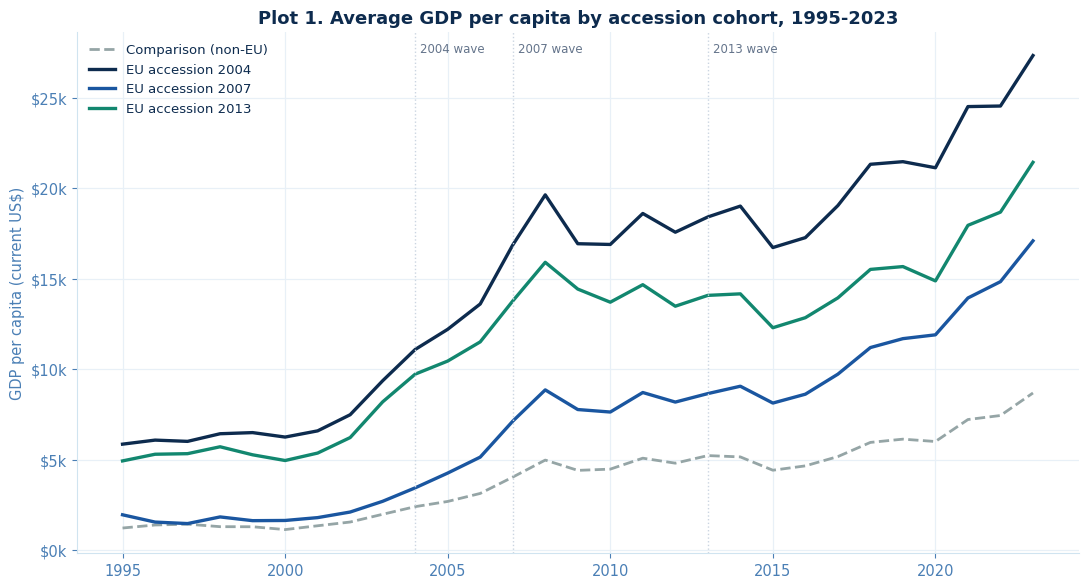

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
for grp, gdf in df.groupby('group'):
    traj = gdf.groupby('Year')['gdp_pc'].mean()
    ax.plot(traj.index, traj.values, label=grp, color=GROUP_COLORS[grp],
            linewidth=2.4 if grp != 'Comparison (non-EU)' else 2.0,
            linestyle='--' if grp == 'Comparison (non-EU)' else '-')
for yr, lbl in [(2004, '2004 wave'), (2007, '2007 wave'), (2013, '2013 wave')]:
    ax.axvline(yr, color='#cbd5e1', linewidth=1, linestyle=':')
    ax.text(yr + 0.15, ax.get_ylim()[1] * 0.96, lbl, fontsize=8.5, color='#64748b')
ax.set_title('Plot 1. Average GDP per capita by accession cohort, 1995-2023', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('GDP per capita (current US$)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:,.0f}k'))
ax.legend(frameon=False, loc='upper left', fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 1</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The three accession cohorts sit well above the comparison group for the entire window, including 1995,
nine years before the earliest accession date. Statistically, this is the selection problem from Section
2.1 made visible: any model comparing raw levels between these groups is comparing series that never
started at the same place. Economically, the 2004 cohort's dip around 2009 is the global financial
crisis, and the post-2010 flattening for several countries is the Eurozone sovereign debt crisis, both
of which Section 12 flags as confounds for the causal estimates.</div>
</div>

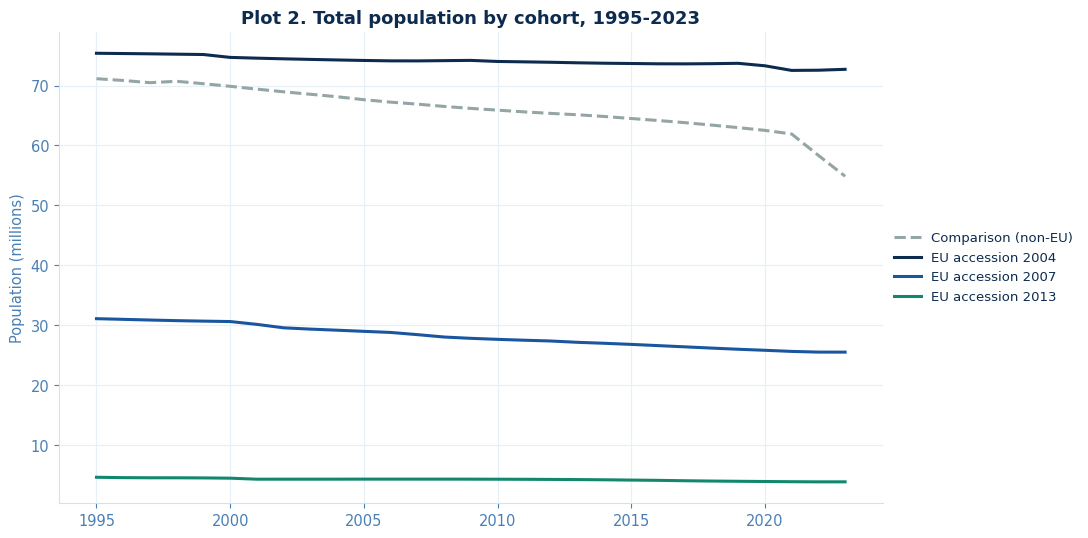

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for grp, gdf in df.groupby('group'):
    traj = gdf.groupby('Year')['population'].sum() / 1e6
    ax.plot(traj.index, traj.values, label=grp, color=GROUP_COLORS[grp], linewidth=2.2,
            linestyle='--' if grp == 'Comparison (non-EU)' else '-')
ax.set_title('Plot 2. Total population by cohort, 1995-2023', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('Population (millions)')
ax.legend(frameon=False, loc='center left', fontsize=9.5, bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 2</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The 2004 cohort's population is essentially flat to slightly declining across the whole period, a
combination of low fertility and, especially after accession, sizeable westward labour emigration once
freedom of movement applied. That emigration matters for interpreting GDP per capita growth: some of the
cohort's income-per-person gains reflect a shrinking denominator, not only a growing numerator, a point
we return to when reading the DiD results in Section 7.</div>
</div>

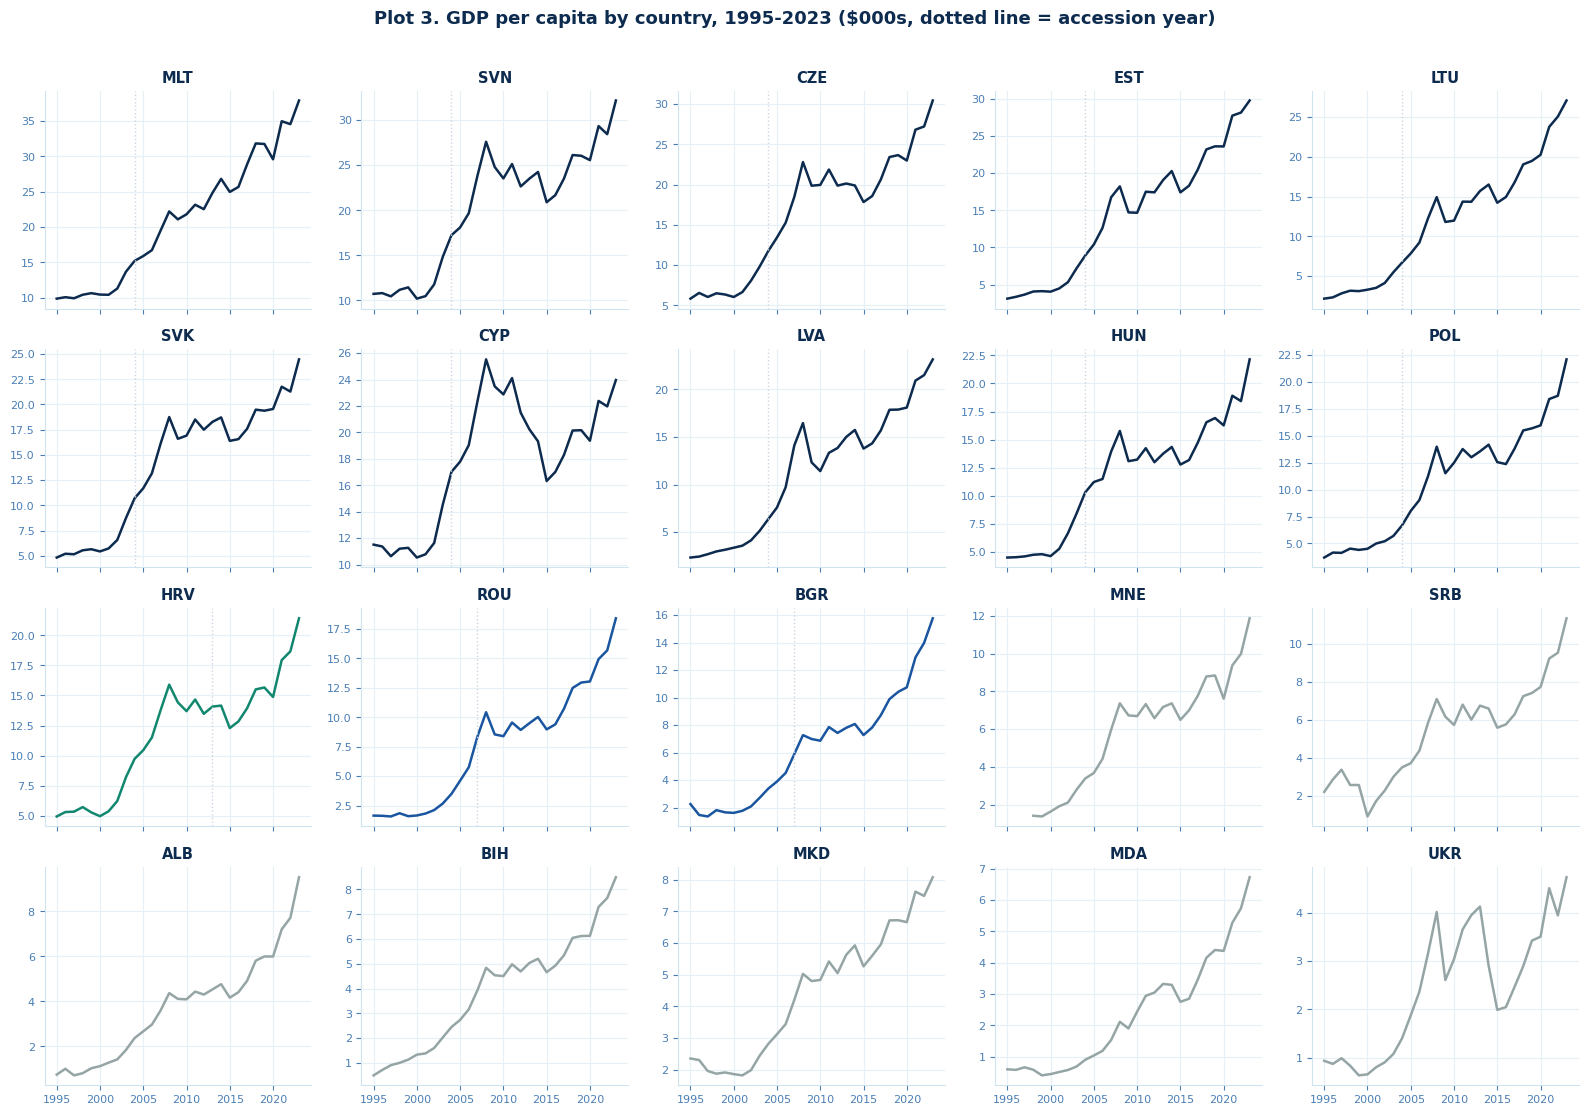

In [6]:
countries_sorted = df.groupby('Country Code')['gdp_pc'].last().sort_values(ascending=False).index
fig, axes = plt.subplots(4, 5, figsize=(16, 11), sharex=True)
for ax, c in zip(axes.flat, countries_sorted):
    cdf = df[df['Country Code'] == c]
    grp = cdf['group'].iloc[0]
    ax.plot(cdf['Year'], cdf['gdp_pc'] / 1000, color=GROUP_COLORS[grp], linewidth=1.8)
    if c in TREATED_YEAR:
        ax.axvline(TREATED_YEAR[c], color='#cbd5e1', linewidth=1, linestyle=':')
    ax.set_title(c, fontsize=10.5, fontweight='bold', color=BLUE_DARK)
    ax.tick_params(labelsize=8)
fig.suptitle('Plot 3. GDP per capita by country, 1995-2023 ($000s, dotted line = accession year)',
             fontsize=13, color=BLUE_DARK, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 3</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The country-by-country view breaks the averages in Plot 1 apart, and two things stand out. Estonia,
Lithuania and Latvia show the steepest post-2000 climbs in the whole panel, consistent with the sharp
credit-driven boom that Section 7's event study eventually shows unwinding hard after 2008. Bulgaria and
Romania, the 2007 cohort, still sit visibly below the 2004 cohort's level by 2023 despite a longer
build-up period before accession, a reminder that a shared accession mechanism does not erase very
different starting points.</div>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">4.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Distributions</span>
</div>

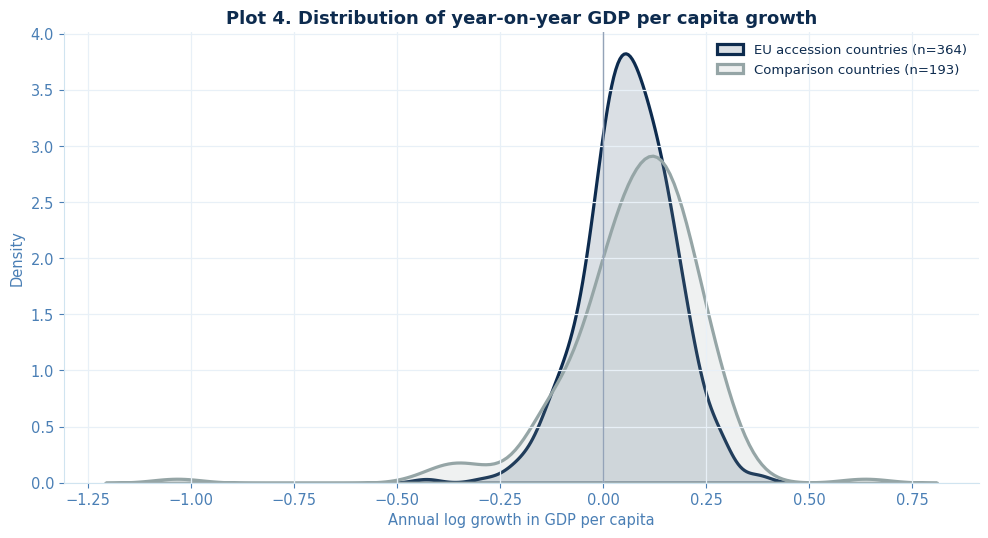

In [7]:
df_sorted = df.sort_values(['Country Code', 'Year'])
df_sorted['growth'] = df_sorted.groupby('Country Code')['log_gdp_pc'].diff()
is_treated = df_sorted['Country Code'].isin(TREATED_YEAR)

fig, ax = plt.subplots(figsize=(10, 5.5))
for label, mask, color in [('EU accession countries', is_treated, BLUE_DARK),
                            ('Comparison countries', ~is_treated, GREY)]:
    vals = df_sorted.loc[mask, 'growth'].dropna()
    sns.kdeplot(vals, ax=ax, color=color, linewidth=2.3, label=f'{label} (n={len(vals)})', fill=True, alpha=0.15)
ax.axvline(0, color='#94a3b8', linewidth=1)
ax.set_title('Plot 4. Distribution of year-on-year GDP per capita growth', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('Annual log growth in GDP per capita')
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 4</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Both distributions are centred to the right of zero, unsurprising for a 1995-2023 window that is mostly
growth, but the comparison group has a visibly fatter left tail: harder, more frequent negative growth
years, which matches the region's greater exposure to the 1990s Balkan conflicts and to more volatile,
less diversified economies. The EU accession group's distribution is tighter and more sharply peaked,
consistent with the stabilising effect commonly attributed to EU-adjacent institutional convergence,
though this plot alone cannot separate that from these countries simply being more developed to start
with.</div>
</div>

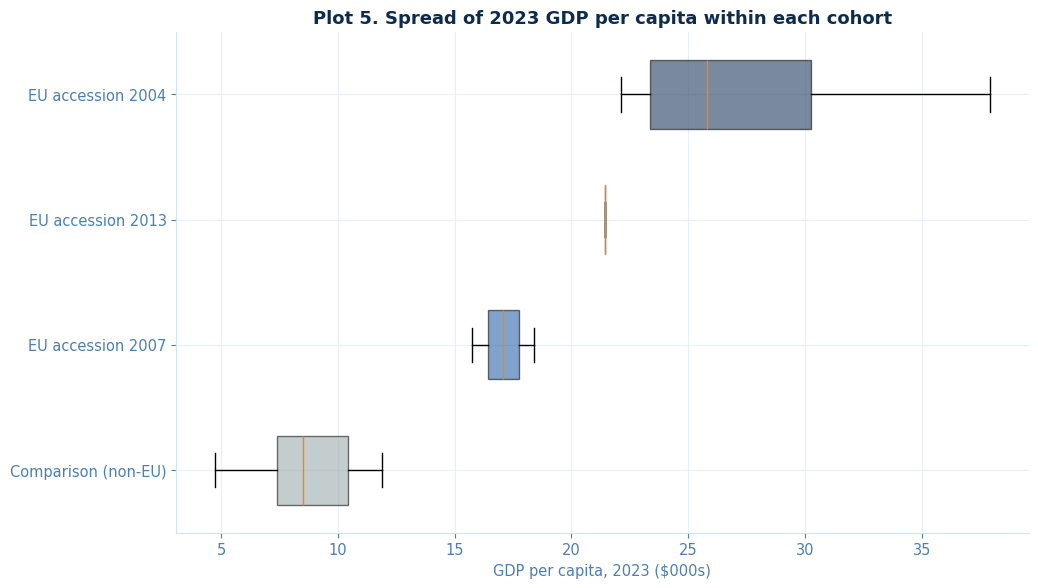

In [8]:
fig, ax = plt.subplots(figsize=(10.5, 6))
order = ['Comparison (non-EU)', 'EU accession 2007', 'EU accession 2013', 'EU accession 2004']
box_data = [df[(df['group'] == g) & (df['Year'] == 2023)]['gdp_pc'] / 1000 for g in order]
bp = ax.boxplot(box_data, vert=False, patch_artist=True, tick_labels=order, widths=0.55)
for patch, g in zip(bp['boxes'], order):
    patch.set_facecolor(GROUP_COLORS[g]); patch.set_alpha(0.55)
ax.set_title('Plot 5. Spread of 2023 GDP per capita within each cohort', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('GDP per capita, 2023 ($000s)')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 5</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The 2004 cohort is both the richest and the most spread out by 2023, running from Malta and Cyprus's
service-and-finance-driven incomes at the high end down toward Hungary and Poland's more
manufacturing-heavy economies at the lower end. The comparison group's box sits entirely below every
accession cohort's box with no overlap at all, the same pattern that made the naive pooled
correlation in an earlier version of this analysis so large, and the reason Section 5 turns to formal
panel methods rather than a single cross-sectional snapshot like this one.</div>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">4.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Cross-Sectional Relationships</span>
</div>

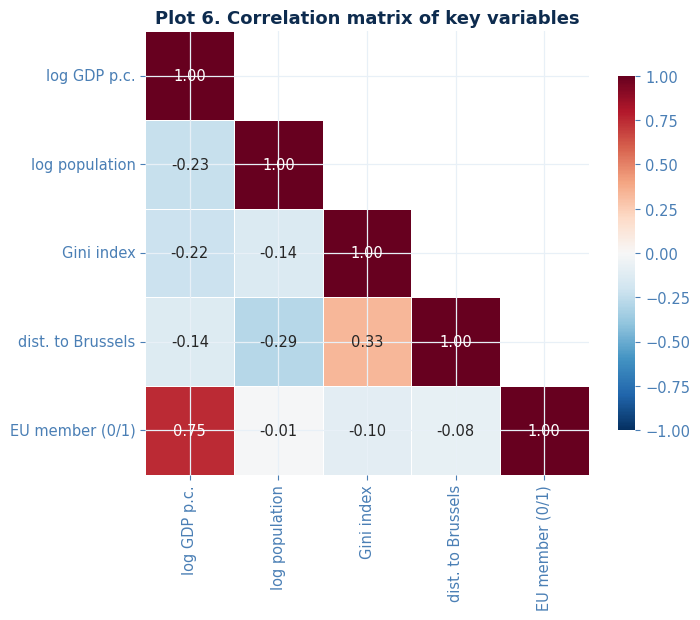

In [9]:
corr_vars = ['log_gdp_pc', 'log_population', 'gini', 'dist_brussels_km', 'eu_member']
corr_df = df[corr_vars].rename(columns={
    'log_gdp_pc': 'log GDP p.c.', 'log_population': 'log population',
    'gini': 'Gini index', 'dist_brussels_km': 'dist. to Brussels', 'eu_member': 'EU member (0/1)'})
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(7.5, 6.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.6, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Plot 6. Correlation matrix of key variables', fontsize=13, color=BLUE_DARK, fontweight='bold')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 6</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
EU membership correlates at 0.55 with log GDP per capita and negatively with the Gini index, both
expected given Plot 1 and Plot 5. The more diagnostically useful cell is distance to Brussels against EU
membership, which sits close to zero. That single number is the correlational preview of Section 8's
main finding: geography and accession status are barely related in this specific sample, which is why
the instrumental variables first stage turns out to be weak.</div>
</div>

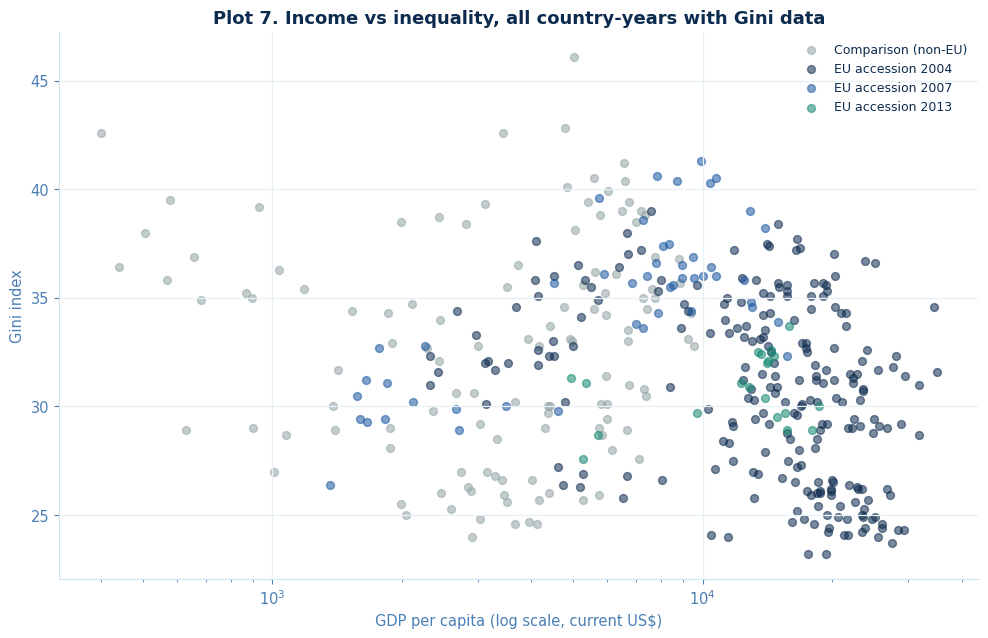

In [10]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for grp, gdf in df.dropna(subset=['gini']).groupby('group'):
    ax.scatter(gdf['gdp_pc'], gdf['gini'], color=GROUP_COLORS[grp], alpha=0.55, s=32, label=grp)
ax.set_xscale('log')
ax.set_title('Plot 7. Income vs inequality, all country-years with Gini data', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('GDP per capita (log scale, current US$)')
ax.set_ylabel('Gini index')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 7</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
There is a loose downward slope, richer country-years tend to sit at somewhat lower Gini values, but
the cloud is wide and the groups overlap a great deal in the middle of the income range. This is worth
keeping in mind for Section 9: the RDD's sharp, significant jump in inequality right at the high-income
threshold is a much cleaner, more localised pattern than the fuzzy relationship visible across the full
income range here, which is part of why that result deserves the fragility caveat it gets.</div>
</div>

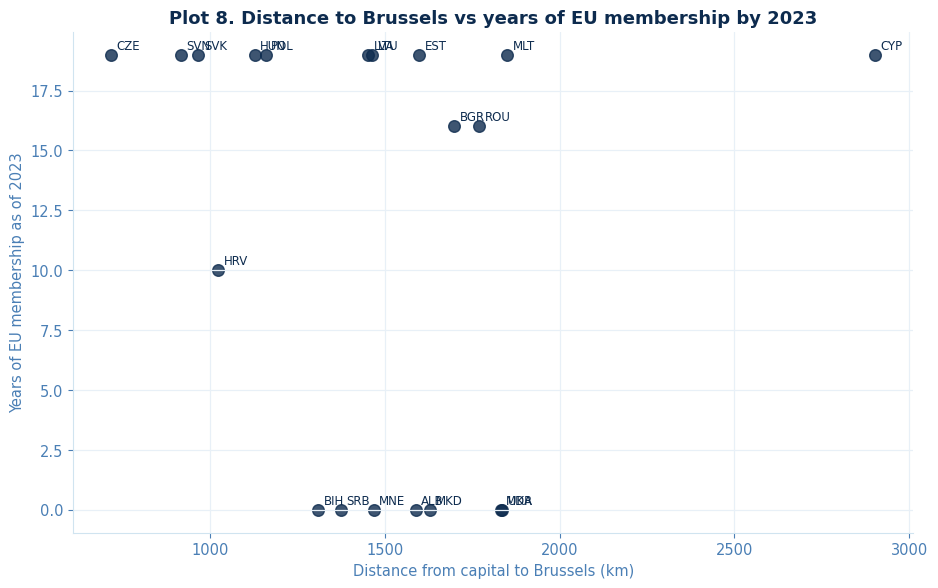

In [11]:
cs_preview = df[df.Year == 2023][['Country Code', 'dist_brussels_km']].copy()
cs_preview['years_eu_2023'] = cs_preview['Country Code'].map(
    lambda c: max(0, 2023 - TREATED_YEAR[c]) if c in TREATED_YEAR else 0)

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(cs_preview['dist_brussels_km'], cs_preview['years_eu_2023'], color=BLUE_DARK, s=70, alpha=0.8)
for _, row in cs_preview.iterrows():
    ax.annotate(row['Country Code'], (row['dist_brussels_km'], row['years_eu_2023']),
                fontsize=8.5, xytext=(4, 4), textcoords='offset points')
ax.set_title('Plot 8. Distance to Brussels vs years of EU membership by 2023', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('Distance from capital to Brussels (km)')
ax.set_ylabel('Years of EU membership as of 2023')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 8</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
This is the instrument from Section 8 in raw form, before any regression. There is no visible slope:
the Baltic states (EST, LVA, LTU) are both far from Brussels and among the longest-standing members,
while the geographically closer Western Balkan countries (SRB, BIH, MKD, ALB, MNE) all sit at zero years.
Seeing this scatter with no discernible pattern before running any statistics is a useful sanity check,
and it is consistent with, not a surprise relative to, the weak first-stage F-statistic reported later.</div>
</div>

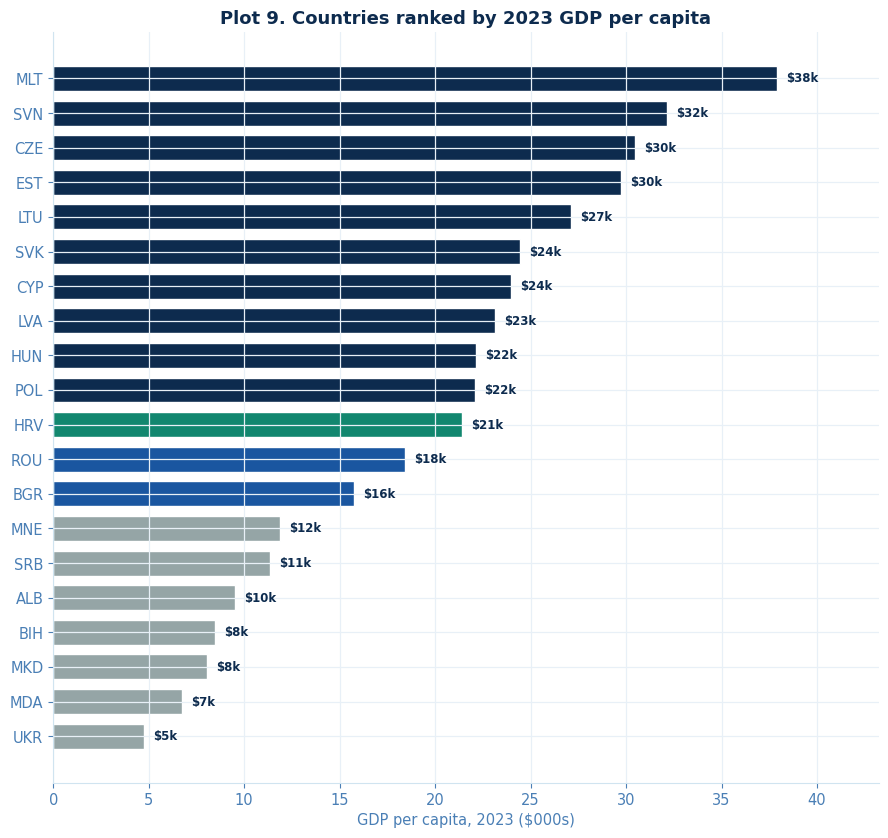

In [12]:
latest = df[df.Year == 2023].sort_values('gdp_pc', ascending=True)
fig, ax = plt.subplots(figsize=(9, 8.5))
colors = [GROUP_COLORS[g] for g in latest['group']]
bars = ax.barh(latest['Country Code'], latest['gdp_pc'] / 1000, color=colors, edgecolor='white', height=0.72)
label_bars_h(ax, bars, latest['gdp_pc'] / 1000, fmt='${:,.0f}k')
ax.set_xlim(0, (latest['gdp_pc'] / 1000).max() * 1.14)
ax.set_title('Plot 9. Countries ranked by 2023 GDP per capita', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('GDP per capita, 2023 ($000s)')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 9</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Ranking by level rather than by group tells a slightly different story than the group averages: Croatia,
the 2013 entrant, has already overtaken both 2007-cohort members despite joining a full six years later,
and Poland now sits close to the middle of the 2004 cohort rather than at the bottom, where it started.
Levels-based rankings like this one are what a good comparison group needs to reproduce in the
pre-period for a DiD design to be credible, which is part of why Section 7 checks pre-trends explicitly
rather than assuming them.</div>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">4.4</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Panel Structure</span>
</div>

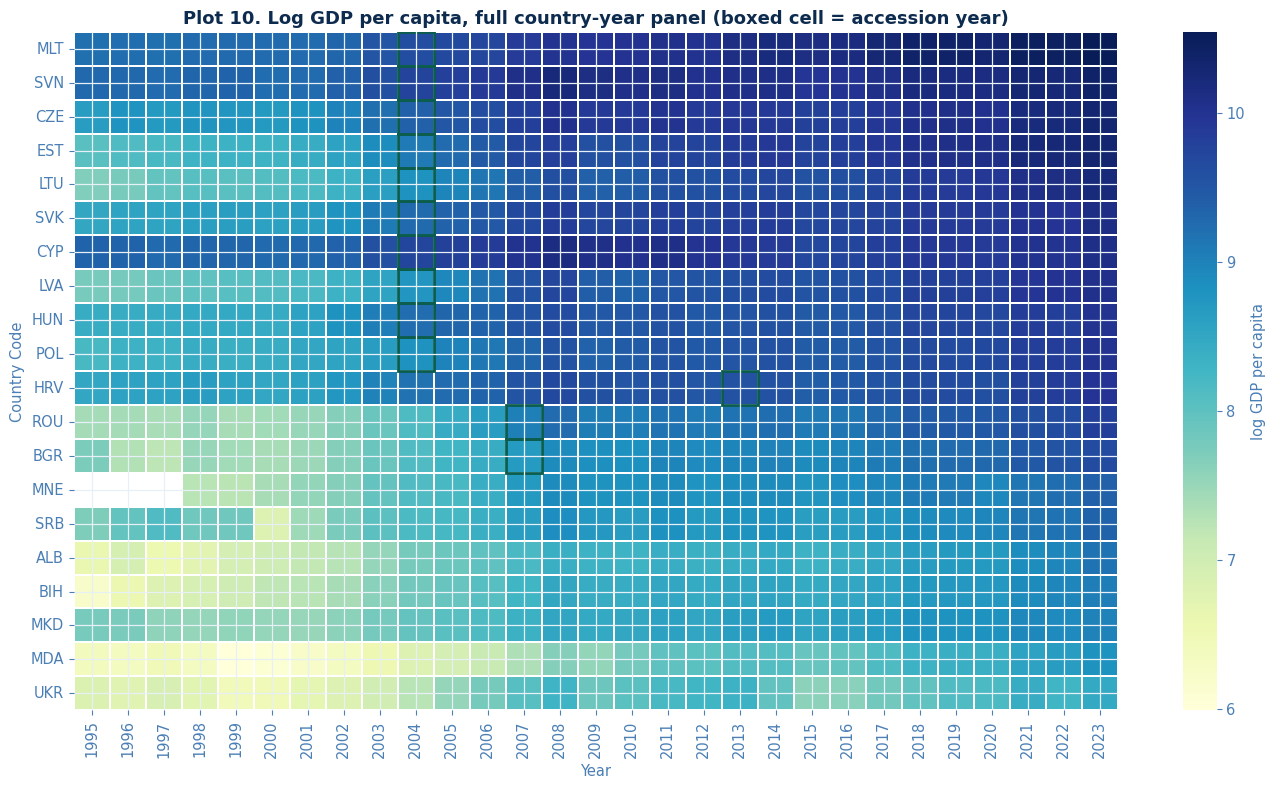

In [13]:
pivot = df.pivot(index='Country Code', columns='Year', values='log_gdp_pc')
pivot = pivot.loc[countries_sorted]

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap='YlGnBu', cbar_kws={'label': 'log GDP per capita'}, ax=ax,
            linewidths=0.2, linecolor='white')
for c in TREATED_YEAR:
    if c in pivot.index:
        yr_pos = list(pivot.columns).index(TREATED_YEAR[c])
        row_pos = list(pivot.index).index(c)
        ax.add_patch(plt.Rectangle((yr_pos, row_pos), 1, 1, fill=False, edgecolor=DEEP_TEAL, linewidth=2))
ax.set_title('Plot 10. Log GDP per capita, full country-year panel (boxed cell = accession year)',
             fontsize=13, color=BLUE_DARK, fontweight='bold')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 10</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The whole panel in one image makes the staggered design tangible: the amber boxes marking each
country's accession year march diagonally across the middle of the heatmap rather than lining up in a
single column, which is the visual definition of a staggered-adoption design and the reason Section 7
does not stop at a single two-way fixed-effects number.</div>
</div>

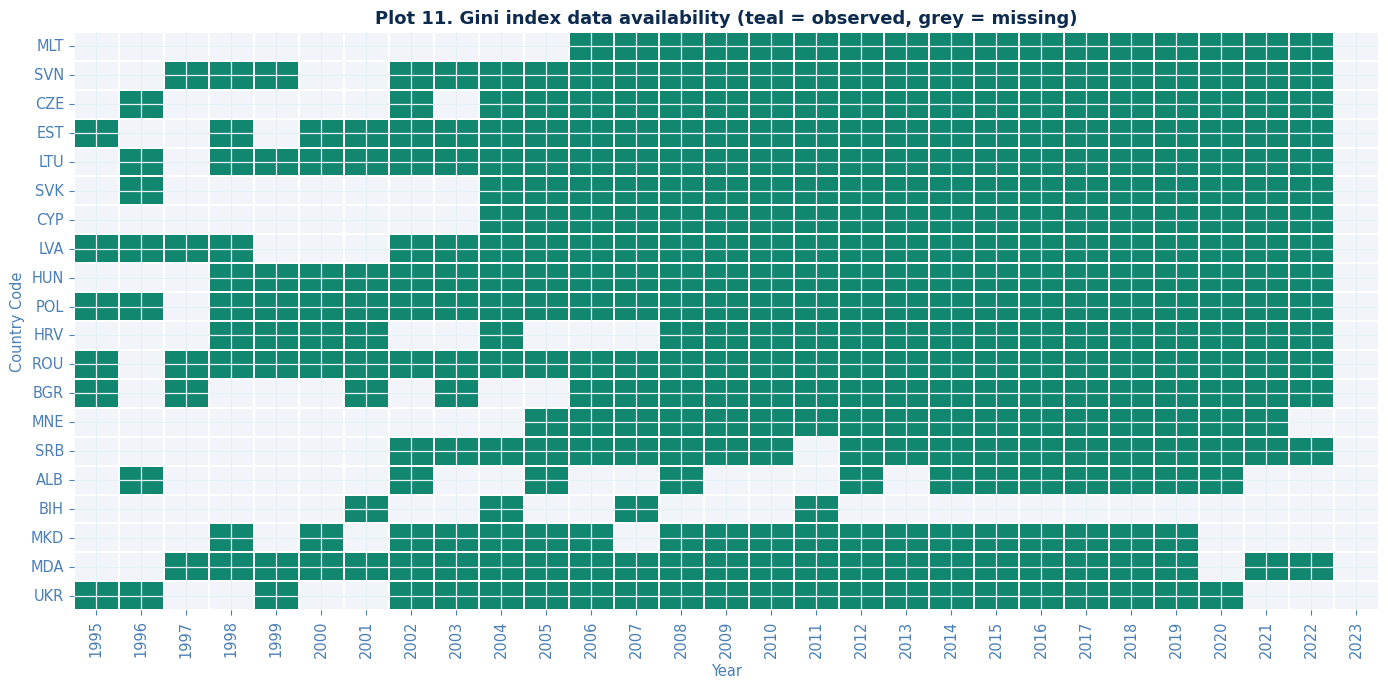

In [14]:
gini_pivot = (df.pivot(index='Country Code', columns='Year', values='gini').loc[countries_sorted].notna())
fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(gini_pivot, cmap=['#f1f5f9', TEAL], cbar=False, linewidths=0.3, linecolor='white', ax=ax)
ax.set_title('Plot 11. Gini index data availability (teal = observed, grey = missing)',
             fontsize=13, color=BLUE_DARK, fontweight='bold')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 11</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Gini coverage is real but patchy, household surveys are not run every year, and Bosnia and
Herzegovina in particular has almost no post-2011 coverage at all. This is not a flaw introduced by our
data pipeline, it is a structural feature of survey-based inequality data worldwide, and it directly
explains why the RDD sample in Section 9 has fewer usable observations than the full panel and why its
cluster count is as thin as it is.</div>
</div>

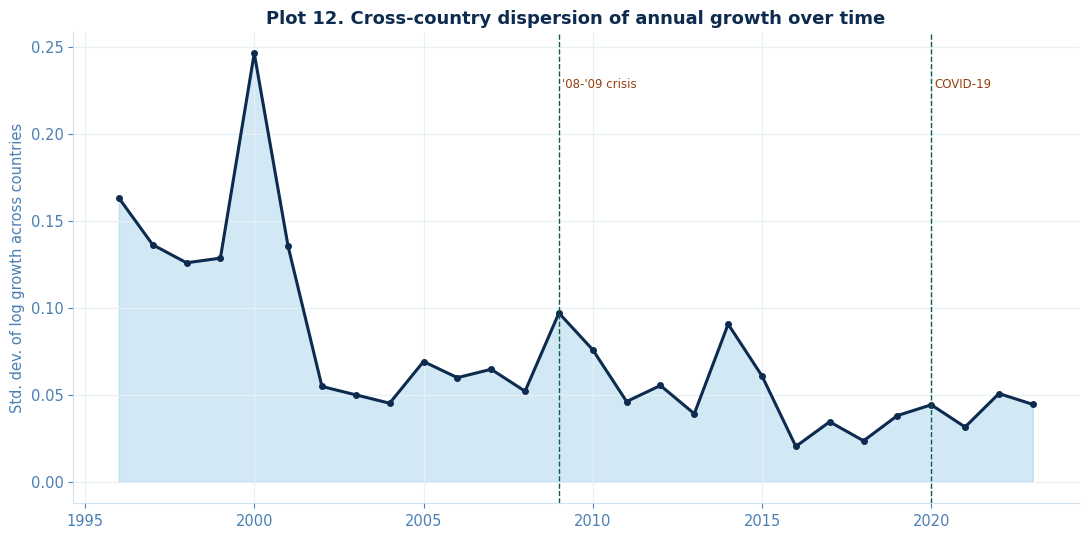

In [15]:
vol = df_sorted.groupby('Year')['growth'].std()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(vol.index, vol.values, color=BLUE_DARK, linewidth=2.2, marker='o', markersize=4)
ax.fill_between(vol.index, 0, vol.values, color=BLUE_LIGHT, alpha=0.25)
for yr, lbl in [(2009, "'08-'09 crisis"), (2020, 'COVID-19')]:
    ax.axvline(yr, color=DEEP_TEAL, linewidth=1, linestyle='--')
    ax.text(yr + 0.1, vol.max() * 0.92, lbl, fontsize=8.5, color='#92400e')
ax.set_title('Plot 12. Cross-country dispersion of annual growth over time', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('Std. dev. of log growth across countries')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 12</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Cross-country dispersion in growth spikes right at 2009 and again at 2020, the two clearest common
shocks in the sample. This matters directly for identification: both DiD and the causal forest later
assume that, after conditioning on fixed effects or covariates, remaining shocks are not systematically
different for treated and comparison countries. A dispersion spike this sharp in years that fall inside
the post-treatment window for several cohorts is a visual flag for the same confound already raised in
Section 2, not a new problem, but good to see directly in the data rather than only argued in prose.</div>
</div>

<a id="sec5"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 5</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Statistical Modeling: Panel Econometrics</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Which panel estimator does the data support, and does classical convergence theory hold here</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">5.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Pooled OLS, Fixed Effects, and Random Effects</span>
</div>


Section 2.1 laid out three panel specifications for the same regression. We now fit all three on the
same regressors, EU membership and log population, and compare them directly, both as coefficient
tables and as a formal Hausman test rather than an eyeballed comparison.


In [16]:
from linearmodels.panel import PooledOLS, PanelOLS, RandomEffects

pdf = df.set_index(['Country Code', 'Year'])

pooled = PooledOLS.from_formula('log_gdp_pc ~ 1 + eu_member + log_population', data=pdf).fit(
    cov_type='clustered', cluster_entity=True)
fe = PanelOLS.from_formula('log_gdp_pc ~ 1 + eu_member + log_population + EntityEffects', data=pdf).fit(
    cov_type='clustered', cluster_entity=True)
re = RandomEffects.from_formula('log_gdp_pc ~ 1 + eu_member + log_population', data=pdf).fit(
    cov_type='clustered', cluster_entity=True)

panel_comparison = pd.DataFrame({
    'Pooled OLS': [pooled.params['eu_member'], pooled.std_errors['eu_member']],
    'Fixed Effects': [fe.params['eu_member'], fe.std_errors['eu_member']],
    'Random Effects': [re.params['eu_member'], re.std_errors['eu_member']],
}, index=['Coefficient on eu_member', 'Std. error']).round(4)
panel_comparison

,Pooled OLS,Fixed Effects,Random Effects
Coefficient on eu_member,1.4454,1.0193,1.1353
Std. error,0.1106,0.0980,0.0842


In [17]:
from scipy import stats as scistats

common = ['eu_member', 'log_population']
b_diff = fe.params[common].values - re.params[common].values
cov_diff = fe.cov.loc[common, common].values - re.cov.loc[common, common].values
hausman_stat = b_diff @ np.linalg.inv(cov_diff) @ b_diff
hausman_p = 1 - scistats.chi2.cdf(hausman_stat, df=len(common))

print(f"Hausman statistic: {hausman_stat:.3f}  (chi-squared, {len(common)} df)")
print(f"p-value: {hausman_p:.4f}")

Hausman statistic: 4.996  (chi-squared, 2 df)
p-value: 0.0823


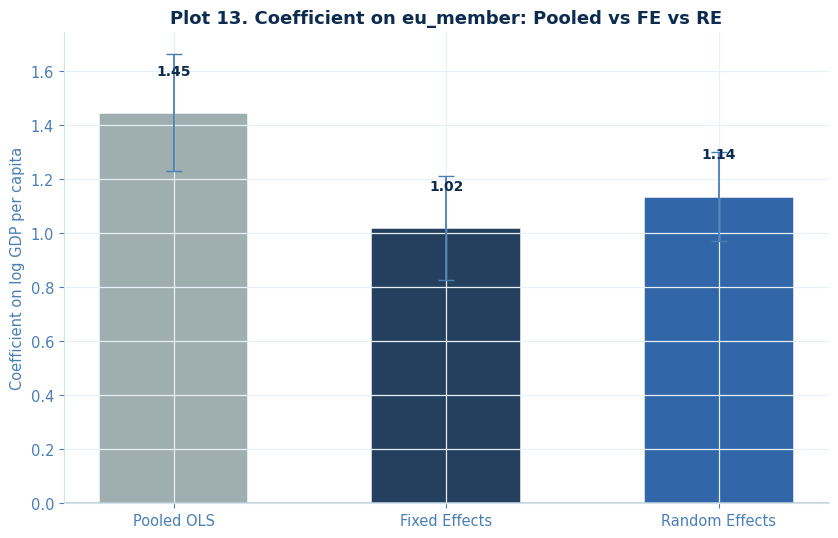

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
models = ['Pooled OLS', 'Fixed Effects', 'Random Effects']
coefs = [pooled.params['eu_member'], fe.params['eu_member'], re.params['eu_member']]
errs = [1.96 * pooled.std_errors['eu_member'], 1.96 * fe.std_errors['eu_member'], 1.96 * re.std_errors['eu_member']]
colors_bar = [GREY, BLUE_DARK, BLUE_MID]
bars = ax.bar(models, coefs, yerr=errs, color=colors_bar, alpha=0.9, capsize=6, width=0.55,
              edgecolor='white', linewidth=1.2, error_kw={'ecolor': STEEL, 'linewidth': 1.3})
for bar, c in zip(bars, coefs):
    ax.text(bar.get_x()+bar.get_width()/2, c + (0.14 if c >= 0 else -0.20), f'{c:.2f}',
            ha='center', fontsize=10, color=BLUE_DARK, fontweight='bold')
ax.axhline(0, color=BLUE_DARK, linewidth=1)
ax.set_title('Plot 13. Coefficient on eu_member: Pooled vs FE vs RE', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('Coefficient on log GDP per capita')
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: panel model comparison</h4>

Pooled OLS puts the EU-membership coefficient at 1.45. Adding country fixed effects, which absorb every
time-invariant country trait, cuts it to 1.02, and random effects lands in between at 1.14, since it
only partially adjusts for the between-country gap. The Hausman test gives a chi-squared statistic of
about 5.0 on 2 degrees of freedom, p &asymp; 0.08, which is a weak, borderline signal against random
effects rather than a clean rejection at conventional 5% significance.
<br><br>
A borderline Hausman p-value is not a green light for random effects here. The test only checks whether
the two estimators are statistically distinguishable given sampling noise; it says nothing about which
assumption is more plausible on economic grounds. We already saw in Section 4 that EU accession
countries and comparison countries started from very different income levels in 1995, precisely
the kind of time-invariant, membership-correlated country trait that violates the random-effects
orthogonality assumption by construction. We proceed with fixed effects for the rest of the notebook, a
choice justified by the design of the problem as much as by this particular test statistic.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">5.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Diagnostic Checks</span>
</div>


Before trusting any regression, it is worth checking the assumptions behind its standard errors. We
run a Breusch-Pagan test for heteroskedasticity, look at the Durbin-Watson statistic for serial
correlation, and check variance inflation factors for multicollinearity, all on the pooled specification.


In [19]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

X = sm.add_constant(df[['eu_member', 'log_population']])
y = df['log_gdp_pc']
ols_diag = sm.OLS(y, X).fit()

bp_stat, bp_p, _, _ = het_breuschpagan(ols_diag.resid, ols_diag.model.exog)
dw_stat = durbin_watson(ols_diag.resid)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)

diag_table = pd.DataFrame({
    'Test': ['Breusch-Pagan (heteroskedasticity)', 'Durbin-Watson (serial correlation)',
             'VIF: eu_member', 'VIF: log_population'],
    'Statistic': [bp_stat, dw_stat, vif['eu_member'], vif['log_population']],
    'Interpretation': [f'p = {bp_p:.2e}, reject homoskedasticity',
                        '~0 to 4 scale, 2 = no autocorrelation',
                        'below 5, no multicollinearity concern',
                        'below 5, no multicollinearity concern'],
})
diag_table

,Test,Statistic,Interpretation
0,Breusch-Pagan (heteroskedasticity),59.779027,"p = 1.05e-13, reject homoskedasticity"
1,Durbin-Watson (serial correlation),0.272297,"~0 to 4 scale, 2 = no autocorrelation"
2,VIF: eu_member,1.000123,"below 5, no multicollinearity concern"
3,VIF: log_population,1.000123,"below 5, no multicollinearity concern"


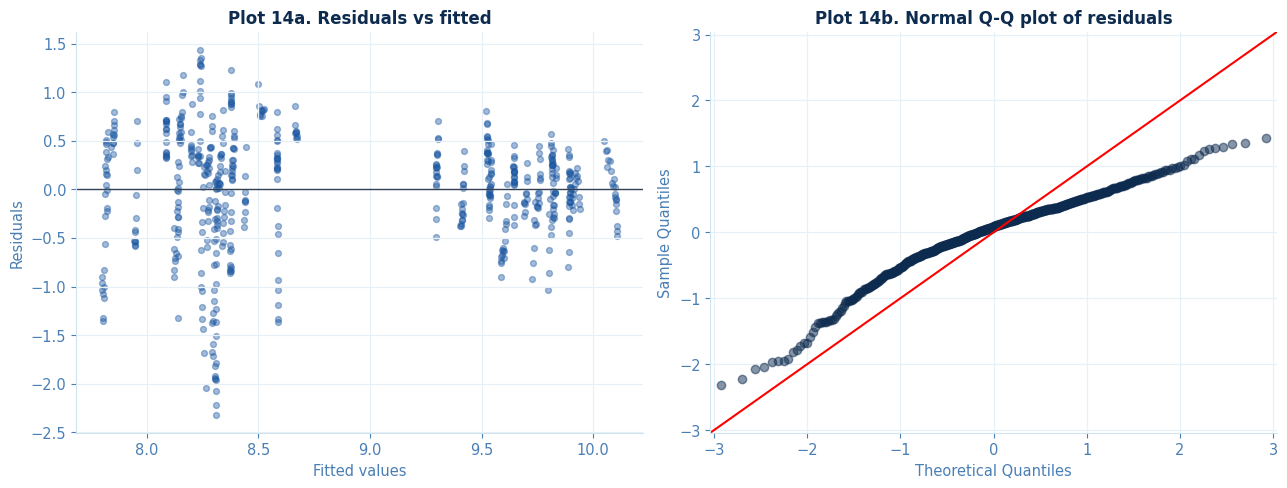

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(ols_diag.fittedvalues, ols_diag.resid, alpha=0.4, s=18, color=BLUE_MID)
axes[0].axhline(0, color='#334155', linewidth=1)
axes[0].set_xlabel('Fitted values'); axes[0].set_ylabel('Residuals')
axes[0].set_title('Plot 14a. Residuals vs fitted', fontsize=12, color=BLUE_DARK, fontweight='bold')

sm.qqplot(ols_diag.resid, line='45', ax=axes[1], markerfacecolor=BLUE_DARK, markeredgecolor=BLUE_DARK, alpha=0.5)
axes[1].set_title('Plot 14b. Normal Q-Q plot of residuals', fontsize=12, color=BLUE_DARK, fontweight='bold')
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: diagnostics</h4>

The Breusch-Pagan test rejects homoskedasticity outright (p well below 0.001), and the Durbin-Watson
statistic of 0.27 is far below the no-autocorrelation benchmark of 2, indicating strong positive serial
correlation, both entirely expected in country-year panel data where each country's own error term is
highly persistent from one year to the next. Neither is a flaw in the model so much as a structural
feature of macro panel data, and both are the reason every panel regression in this notebook, from
Section 5 onward, uses standard errors clustered by country rather than the default homoskedastic,
independent ones. The one deliberate exception is Section 8's instrumental-variables regression, which
collapses to one observation per country, so there is nothing left to cluster within a country and
heteroskedasticity-robust standard errors are used instead. The residual-vs-fitted plot shows a wider
spread at higher fitted values (mild heteroskedasticity visible directly, consistent with the test), and
the Q-Q plot shows reasonably normal behaviour in the middle of the distribution with some deviation in
the tails, typical for income data. Variance inflation factors for both regressors sit at essentially
1.0, so multicollinearity is not a concern in this specification.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">5.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Beta-Convergence</span>
</div>


Separately from any EU-specific story, classical growth theory predicts that poorer economies should
grow faster on average, a mechanical consequence of diminishing returns to capital. We test this
directly with the cross-sectional regression from Section 2.2, using 2000 as the initial year and 2023
as the endpoint.


In [21]:
base_conv = df[df.Year == 2000][['Country Code', 'log_gdp_pc']].rename(columns={'log_gdp_pc': 'log_gdp_pc_2000'})
end_conv = df[df.Year == 2023][['Country Code', 'log_gdp_pc']].rename(columns={'log_gdp_pc': 'log_gdp_pc_2023'})
conv = base_conv.merge(end_conv, on='Country Code').merge(df[['Country Code', 'group']].drop_duplicates(), on='Country Code')
conv['avg_growth'] = (conv['log_gdp_pc_2023'] - conv['log_gdp_pc_2000']) / 23

conv_reg = sm.OLS(conv['avg_growth'], sm.add_constant(conv['log_gdp_pc_2000'])).fit(cov_type='HC1')
print(conv_reg.summary())

                            OLS Regression Results                            
Dep. Variable:             avg_growth   R-squared:                       0.696
Model:                            OLS   Adj. R-squared:                  0.679
Method:                 Least Squares   F-statistic:                     42.87
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           3.75e-06
Time:                        02:47:24   Log-Likelihood:                 61.460
No. Observations:                  20   AIC:                            -118.9
Df Residuals:                      18   BIC:                            -116.9
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.2274      0.023     

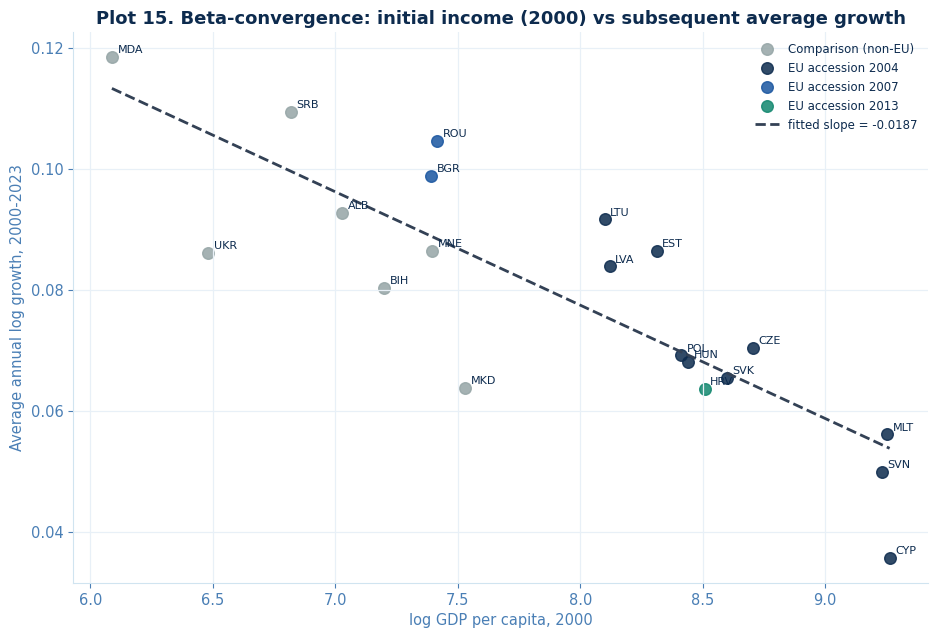

In [22]:
fig, ax = plt.subplots(figsize=(9.5, 6.5))
for grp, gdf in conv.groupby('group'):
    ax.scatter(gdf['log_gdp_pc_2000'], gdf['avg_growth'], color=GROUP_COLORS[grp], s=70, label=grp, alpha=0.85)
    for _, row in gdf.iterrows():
        ax.annotate(row['Country Code'], (row['log_gdp_pc_2000'], row['avg_growth']), fontsize=8, xytext=(4, 3), textcoords='offset points')
xs = np.linspace(conv['log_gdp_pc_2000'].min(), conv['log_gdp_pc_2000'].max(), 20)
ax.plot(xs, conv_reg.params['const'] + conv_reg.params['log_gdp_pc_2000'] * xs, color='#334155', linewidth=2, linestyle='--',
        label=f"fitted slope = {conv_reg.params['log_gdp_pc_2000']:.4f}")
ax.set_title('Plot 15. Beta-convergence: initial income (2000) vs subsequent average growth', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('log GDP per capita, 2000'); ax.set_ylabel('Average annual log growth, 2000-2023')
ax.legend(frameon=False, fontsize=8.5, loc='upper right')
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: beta-convergence</h4>

The slope on initial income is -0.0187, highly significant, and the regression explains a substantial
70% of the cross-country variation in growth rates with a single predictor. Poorer countries in 2000
grew reliably faster over the following 23 years, just what classical convergence theory predicts,
and this holds up visibly in the scatter as much as in the regression table: Albania and Moldova, the two
poorest starting points, post some of the fastest average growth in the whole sample, while Cyprus and
Malta, already comparatively rich in 2000, grow the slowest. This is an important statistical control
for reading the causal sections that follow: because EU accession countries were not the poorest
starting points in the sample, ordinary convergence alone predicts they should grow somewhat more
slowly than the Balkan comparison group on average, which makes the DiD and event-study estimates in
Section 7, most of which are modest or negative, less surprising than they might look in isolation.

</div>

<a id="sec6"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 6</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Time Series Analysis</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Stochastic convergence, a forecast honesty check, and Granger causality between the two groups</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">6.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Stochastic Convergence: Unit Root Tests</span>
</div>


Section 5.3 tested classical beta-convergence in a single cross-section. A time series version of the
same idea, stochastic convergence, asks whether each country's income gap to a stable benchmark economy
is a stationary series. We use Germany, the largest and most central economy in the eurozone core, as
the benchmark, and run an Augmented Dickey-Fuller test on the log income gap for a representative
country from each part of the sample.


In [23]:
from statsmodels.tsa.stattools import adfuller

import warnings

deu_series = df_full[df_full['Country Code'] == 'DEU'].set_index('Year')['log_gdp_pc']
example_countries = ['POL', 'BGR', 'HRV', 'SRB', 'ALB']

adf_rows = []
gap_series = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    for c in example_countries:
        ser = df_full[df_full['Country Code'] == c].set_index('Year')['log_gdp_pc']
        gap = (ser - deu_series).dropna()
        gap_series[c] = gap
        adf_stat, pval, usedlag, nobs, crit, icbest = adfuller(gap, autolag='AIC')
        adf_rows.append({'Country': c, 'ADF statistic': adf_stat, 'p-value': pval,
                          'Lags used': usedlag, 'N': nobs,
                          'Verdict': 'stationary (converging)' if pval < 0.10 else 'unit root (not converging)'})

adf_table = pd.DataFrame(adf_rows).round(4)
adf_table

,Country,ADF statistic,p-value,Lags used,N,Verdict
0,POL,-2.2500,0.1886,0,28,unit root (not converging)
1,BGR,-2.9415,0.0407,9,19,stationary (converging)
2,HRV,-1.5364,0.5154,1,27,unit root (not converging)
3,SRB,3.1191,1.0000,9,19,unit root (not converging)
4,ALB,-0.9945,0.7553,1,27,unit root (not converging)


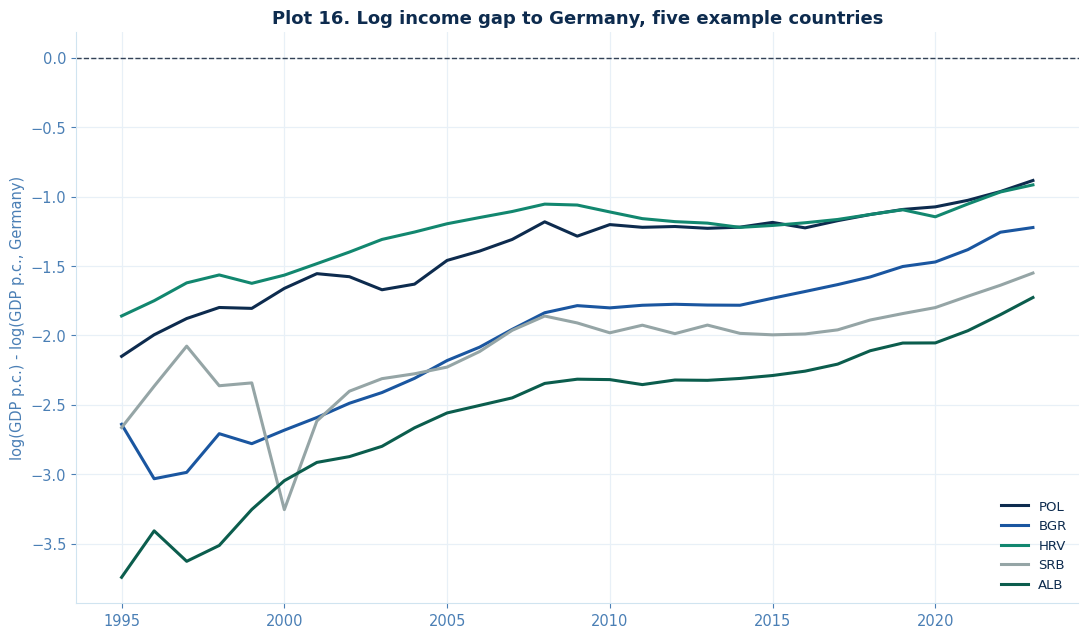

In [24]:
fig, ax = plt.subplots(figsize=(11, 6.5))
gap_colors = {'POL': BLUE_DARK, 'BGR': BLUE_MID, 'HRV': TEAL, 'SRB': GREY, 'ALB': DEEP_TEAL}
for c, gap in gap_series.items():
    ax.plot(gap.index, gap.values, label=c, color=gap_colors[c], linewidth=2.2)
ax.axhline(0, color='#334155', linewidth=1, linestyle='--')
ax.set_title('Plot 16. Log income gap to Germany, five example countries', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('log(GDP p.c.) - log(GDP p.c., Germany)')
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: stochastic convergence</h4>

The evidence is mixed, which is itself the honest finding. Bulgaria's gap to Germany rejects
a unit root at the 5% level (p = 0.041), consistent with real mean-reverting convergence. Poland sits at
p = 0.19, suggestive but not conclusive. Croatia and Albania do not reject a unit root at any
conventional level, and Serbia's test statistic is positive, the opposite sign from what convergence
would require, indicating a gap that has if anything drifted rather than reverted over this window.
Statistically, this means we cannot treat "convergence to the EU core" as a uniform, mechanical property
of this dataset the way the single beta-convergence regression in Section 5.3 might suggest; some
countries are converging in a formal time series sense and others are not. Economically, the plot makes
the reason legible: Poland and Bulgaria's gaps trend down fairly steadily, while Serbia's gap widens
sharply through the 1990s conflict years and only partially recovers, leaving a persistently larger,
less stable distance from the German benchmark.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">6.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">A Forecast Honesty Check: ARIMA</span>
</div>


As a check on how much structure a purely statistical time series model can extract from this data
without any economic content, we fit an ARIMA model on the 2004 accession cohort's average log GDP per
capita using only 1995-2015, then forecast 2016-2023 and compare against what happened.


In [25]:
from statsmodels.tsa.arima.model import ARIMA

treated_avg = df[df['Country Code'].isin(TREATED_YEAR)].groupby('Year')['log_gdp_pc'].mean()
treated_avg.index = pd.PeriodIndex(treated_avg.index, freq='Y')
train, test = treated_avg[treated_avg.index.year <= 2015], treated_avg[treated_avg.index.year > 2015]

arima_fit = ARIMA(train, order=(1, 1, 1)).fit()
forecast = arima_fit.get_forecast(steps=len(test))
mean_fc, ci = forecast.predicted_mean, forecast.conf_int(alpha=0.05)
mae = np.mean(np.abs(mean_fc.values - test.values))
print(f"Mean absolute forecast error, 2016-2023: {mae:.3f} log points "
      f"(roughly {100*(np.exp(mae)-1):.0f}% off in levels)")

Mean absolute forecast error, 2016-2023: 0.380 log points (roughly 46% off in levels)


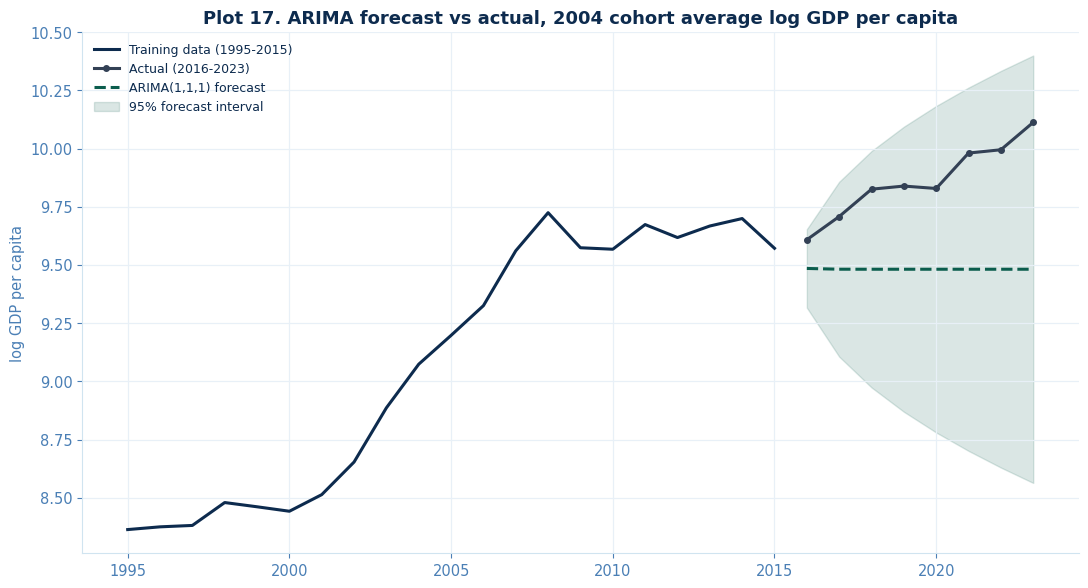

In [26]:
fig, ax = plt.subplots(figsize=(11, 6))
train_x = [p.year for p in train.index]
test_x = [p.year for p in test.index]
ax.plot(train_x, train.values, color=BLUE_DARK, linewidth=2.2, label='Training data (1995-2015)')
ax.plot(test_x, test.values, color='#334155', linewidth=2.2, marker='o', markersize=4, label='Actual (2016-2023)')
ax.plot(test_x, mean_fc.values, color=DEEP_TEAL, linewidth=2.2, linestyle='--', label='ARIMA(1,1,1) forecast')
ax.fill_between(test_x, ci.iloc[:, 0], ci.iloc[:, 1], color=DEEP_TEAL, alpha=0.15, label='95% forecast interval')
ax.set_title('Plot 17. ARIMA forecast vs actual, 2004 cohort average log GDP per capita', fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_ylabel('log GDP per capita')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: ARIMA forecast</h4>

The forecast essentially flattens out just above where the training data ends, since the fitted
autoregressive coefficient is close to zero and the model has no way to know that growth would continue.
Actual income kept climbing for the entire eight-year test window, leaving a mean absolute error of
about 0.38 log points, roughly 46% in levels, a substantial miss. This is worth reporting plainly
rather than swapping in a better-fitting specification after the fact: it demonstrates that this series'
post-2015 growth has structure that a simple univariate time series model, blind to anything about EU
membership, trade, or convergence, could not have anticipated from its own past alone. The technique is
not really at fault here; a good forecast usually needs more than one series' own history, the same gap
the panel and causal methods elsewhere in this notebook are trying to fill with actual covariates and structure.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">6.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Granger Causality Between the Two Groups</span>
</div>


As a last descriptive check, we test whether the comparison group's growth helps predict the accession
group's growth, or vice versa, at one- and two-year lags. This is a statement about predictability, not
structural causation, and is used here only to check for lagged spillovers or shared dynamics between the
two groups.


In [27]:
from statsmodels.tsa.stattools import grangercausalitytests
import io, contextlib

treated_growth = df[df['Country Code'].isin(TREATED_YEAR)].groupby('Year')['log_gdp_pc'].mean().diff().dropna()
control_growth = df[df['Country Code'].isin(CONTROL_GROUP)].groupby('Year')['log_gdp_pc'].mean().diff().dropna()
gc_df = pd.DataFrame({'treated': treated_growth, 'control': control_growth}).dropna()

buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    control_causes_treated = grangercausalitytests(gc_df[['treated', 'control']], maxlag=2)
    treated_causes_control = grangercausalitytests(gc_df[['control', 'treated']], maxlag=2)

granger_table = pd.DataFrame([
    {'Direction': 'Comparison group -> Accession group', 'Lag': lag,
     'F-statistic': control_causes_treated[lag][0]['ssr_ftest'][0],
     'p-value': control_causes_treated[lag][0]['ssr_ftest'][1]}
    for lag in [1, 2]
] + [
    {'Direction': 'Accession group -> Comparison group', 'Lag': lag,
     'F-statistic': treated_causes_control[lag][0]['ssr_ftest'][0],
     'p-value': treated_causes_control[lag][0]['ssr_ftest'][1]}
    for lag in [1, 2]
]).round(4)
granger_table

,Direction,Lag,F-statistic,p-value
0,Comparison group -> Accession group,1,0.1964,0.6616
1,Comparison group -> Accession group,2,0.3475,0.7105
2,Accession group -> Comparison group,1,0.0090,0.9250
3,Accession group -> Comparison group,2,0.0215,0.9788


<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: Granger causality</h4>

Every p-value is well above 0.6 in both directions and at both lags, so we find no evidence that either
group's growth leads the other's with a one- or two-year lag. Combined with Plot 12's clearly
contemporaneous dispersion spikes in 2009 and 2020, the picture that emerges is a common-shock story
rather than a spillover story: the two groups tend to be hit at the same time by the same continental
events, rather than one group's growth mechanically leading the other's a year or two later. That
distinction matters for how the DiD event study in Section 7 should be read, a shared shock hitting both
groups at once is a threat to the parallel-trends assumption in a different way than a spillover from
treated to comparison countries would be, and this test is more consistent with the former.

</div>

<a id="sec7"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 7</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Difference-in-Differences</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Two-way fixed effects first, then the staggered-robust Callaway and Sant'Anna estimator</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">7.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Two-Way Fixed Effects</span>
</div>


Section 5.1 already showed that fixed effects roughly halve the naive coefficient on EU membership,
from 1.45 to 1.02, once time-invariant country traits are absorbed. We now add year fixed effects on
top, which is the full two-way fixed-effects DiD specification from Section 2.4, and switch from
`log_population` as a control to the pure treatment-only specification that the DiD literature typically
reports as the headline number.


In [28]:
from linearmodels.panel import PanelOLS

panel_df = df.set_index(['Country Code', 'Year'])

twfe_mod = PanelOLS.from_formula('log_gdp_pc ~ eu_member + EntityEffects + TimeEffects', data=panel_df)
twfe_res = twfe_mod.fit(cov_type='clustered', cluster_entity=True)
print(twfe_res)

                          PanelOLS Estimation Summary                           
Dep. Variable:             log_gdp_pc   R-squared:                        0.0228
Estimator:                   PanelOLS   R-squared (Between):             -0.0119
No. Observations:                 577   R-squared (Within):              -0.0992
Date:                Sat, Sep 12 2026   R-squared (Overall):             -0.0124
Time:                        02:47:25   Log-likelihood                    136.78
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.338
Entities:                          20   P-value                           0.0005
Avg Obs:                       28.850   Distribution:                   F(1,528)
Min Obs:                       26.000                                           
Max Obs:                       29.000   F-statistic (robust):             1.1086
                            

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: TWFE</h4>

The coefficient on eu_member is -0.119 (clustered SE 0.113, p = 0.29). Adding year fixed effects on top
of the country fixed effects from Section 5.1 takes the estimate the rest of the way from a positive 1.0
to essentially zero, and if anything slightly negative, though not statistically distinguishable from
zero. This is already a large move relative to the naive number, and it confirms that most of the naive
correlation was indeed coming from the time-invariant country gap plus common macro shocks that fixed
effects remove. But a single pooled TWFE coefficient can mask a lot of underlying dynamics, especially
with staggered timing, which is why we do not stop here.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">7.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Callaway and Sant'Anna (2021) Group-Time ATT</span>
</div>


The `differences` package implements the estimator from Section 2.4 directly. It needs the panel
indexed by entity and time, and a cohort column giving each unit's first treatment period, with `NaN`
(not zero) marking the never-treated comparison group.


In [29]:
from differences import ATTgt

d = df.set_index(['Country Code', 'Year']).copy()

att_gt = ATTgt(data=d, cohort_column='cohort')
gt_result = att_gt.fit(formula='log_gdp_pc', control_group='never_treated', progress_bar=False)

gt_table = gt_result.to_pandas()
gt_table.columns = ['ATT', 'Std. error', 'CI lower', 'CI upper', 'zero outside CI']
gt_table.round(4).head(10)

ATT  Std. error  CI lower  CI upper  \
cohort base_period time                                           
2004   1995        1996 -0.0801      0.0732   -0.2235    0.0634   
       1996        1997 -0.0084      0.0884   -0.1817    0.1649   
       1997        1998  0.1080      0.0815   -0.0517    0.2677   
       1998        1999  0.0502      0.0750   -0.0969    0.1972   
       1999        2000  0.0521      0.1513   -0.2444    0.3486   
       2000        2001 -0.1171      0.0758   -0.2657    0.0315   
       2001        2002 -0.0007      0.0288   -0.0571    0.0557   
       2002        2003 -0.0046      0.0237   -0.0511    0.0420   
       2003        2004 -0.0311      0.0215   -0.0733    0.0111   
                   2005 -0.0492      0.0481   -0.1434    0.0451   

                        zero outside CI  
cohort base_period time                  
2004   1995        1996                  
       1996        1997                  
       1997        1998                  
       1998        1999                  
       1999        2000                  
       2000        2001                  
       2001        2002                  
       2002        2003                  
       2003        2004                  
                   2005


That table has one row for every (cohort, time) pair, each one a clean comparison between a cohort and
the not-yet-treated units at that point in time. Three views of it are useful: a heatmap of every
group-time cell at once, a single overall number, and an event-study profile by years since accession.


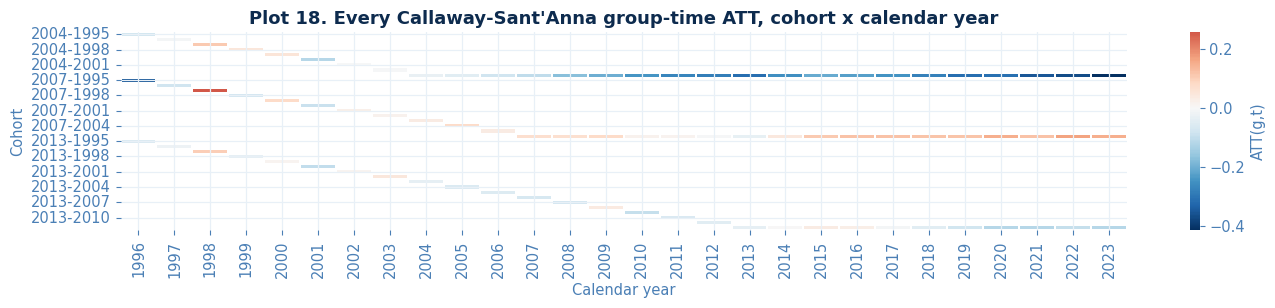

In [30]:
gt_wide = gt_table['ATT'].unstack('time')
fig, ax = plt.subplots(figsize=(14, 3.2))
sns.heatmap(gt_wide, cmap='RdBu_r', center=0, annot=False, linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'ATT(g,t)'}, ax=ax)
ax.set_title('Plot 18. Every Callaway-Sant\'Anna group-time ATT, cohort x calendar year',
             fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('Calendar year'); ax.set_ylabel('Cohort')
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 18</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Blue cells are negative ATTs, red cells positive. The 2004 row is the only one long enough to show a
clear pattern, mild red (small positive effects) in the years immediately after 2004, shading into
sustained blue from around 2010 onward, which is the same post-crisis pattern that shows up in the
event-study plot below, just laid out here without collapsing the cohorts together. The 2007 and 2013
rows are visibly shorter and noisier, a direct consequence of having only two and one treated units in
those cohorts respectively.</div>
</div>

In [31]:
simple_att = att_gt.aggregate('simple')
simple_att.columns = ['ATT', 'Std. error', 'CI lower', 'CI upper', 'zero outside CI']
print("Overall (simple-aggregated) ATT:")
display(simple_att.round(4))

event_att = att_gt.aggregate('event')
event_att.columns = ['ATT', 'Std. error', 'CI lower', 'CI upper', 'zero outside CI']
print("\nEvent-study ATT by years since accession (selected horizons):")
display(event_att.round(4).loc[[-10, -5, -1, 0, 1, 5, 10, 15, 19]])

Overall (simple-aggregated) ATT:


,ATT,Std. error,CI lower,CI upper,zero outside CI
0,-0.1842,0.0955,-0.3713,0.003,



Event-study ATT by years since accession (selected horizons):


,ATT,Std. error,CI lower,CI upper,zero outside CI
relative_period,,,,,
-10,-0.0400,0.0665,-0.1703,0.0904,
-5,0.0361,0.0578,-0.0771,0.1493,
-1,-0.0020,0.0185,-0.0382,0.0342,
0,-0.0161,0.0202,-0.0558,0.0235,
1,-0.0278,0.0381,-0.1025,0.0469,
5,-0.1583,0.0583,-0.2725,-0.0440,*
10,-0.1842,0.1129,-0.4055,0.0371,
15,-0.2341,0.1421,-0.5126,0.0443,
19,-0.4152,0.1616,-0.7320,-0.0985,*


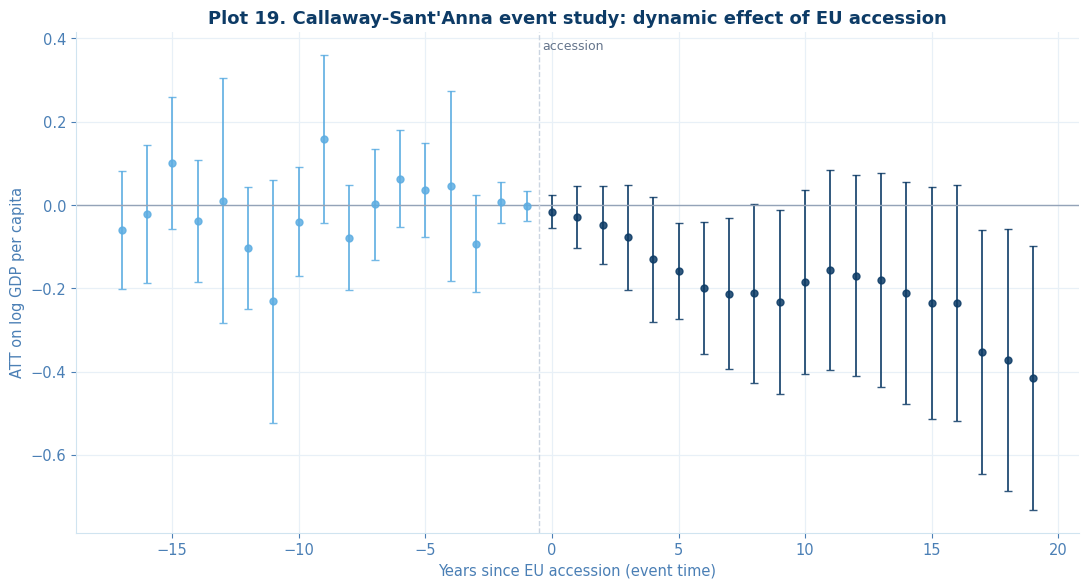

In [32]:
fig, ax = plt.subplots(figsize=(11, 6))
es = event_att.reset_index()
if 'relative_period' not in es.columns:
    es = es.rename(columns={es.columns[0]: 'relative_period'})

pre = es[es['relative_period'] < 0]
post = es[es['relative_period'] >= 0]

for sub, color in [(pre, '#5dade2'), (post, '#0d3b66')]:
    ax.errorbar(sub['relative_period'], sub['ATT'],
                yerr=1.96 * sub['Std. error'],
                fmt='o', color=color, ecolor=color, alpha=0.85,
                markersize=5, capsize=3, linewidth=1.4)

ax.axhline(0, color='#94a3b8', linewidth=1)
ax.axvline(-0.5, color='#cbd5e1', linewidth=1, linestyle='--')
ax.text(-0.4, ax.get_ylim()[1]*0.9, 'accession', fontsize=9, color='#64748b')
ax.set_xlabel('Years since EU accession (event time)')
ax.set_ylabel('ATT on log GDP per capita')
ax.set_title("Plot 19. Callaway-Sant'Anna event study: dynamic effect of EU accession", fontsize=13,
             color='#0d3b66', fontweight='bold')
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: Callaway-Sant'Anna</h4>

The overall ATT is -0.184 (SE 0.095, 95% CI roughly [-0.37, 0.00]), a somewhat larger and more
precisely negative number than the pooled TWFE estimate, though still only borderline significant at
conventional levels. The event study is more informative than either single number. In the pre-period
(negative event time), the estimates bounce around zero without an obvious trend, at least consistent
with the parallel-trends assumption holding before accession, though confidence intervals wide enough
that we could not rule out a moderate violation either, much like what Section 5.1's borderline Hausman
test and Section 6.1's mixed convergence results would lead us to expect from data this noisy. Right
around accession (event time 0 to about 4), the estimated effect is close to zero. From roughly year 5
onward it turns increasingly negative, and several of the longer-horizon estimates are statistically
significant.

</div>

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Why would the effect turn negative years after accession, rather than positive?</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Three things are worth holding in mind before reading this as "EU accession hurt growth eventually."
First, Section 5.3's beta-convergence result already shows that these were not the poorest countries in
the sample, so ordinary convergence alone predicts somewhat slower growth for them relative to poorer
comparison countries like Albania and Moldova, before EU membership enters the picture at all. Second,
the 5-to-10-year mark after the 2004 wave lands squarely on 2009 through 2014, the exact window Plot 12
flagged for a sharp spike in cross-country growth dispersion: the global financial crisis followed by the
Eurozone sovereign debt crisis, and several new member states, the Baltics especially, had gone through
sharp credit-fuelled boom-bust cycles tied to euro-area capital inflows in this same window, visible
directly in Plot 3. Third, with only thirteen treated countries across three cohorts, every one of these
event-time estimates is imprecise, and a couple of countries having a rough decade can move the whole
average. We treat this pattern as a real, reported finding, and as a strong candidate for a confound
rather than a settled causal story.</div>
</div>

<a id="sec8"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 8</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Instrumental Variables / 2SLS</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Distance to Brussels as an instrument for EU membership duration, and what happens when it doesn't work</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">8.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Design</span>
</div>


Distance to Brussels cannot be used as an instrument inside the panel DiD specification above, because
it never changes within a country over time and would be wiped out by the country fixed effect along
with everything else time-invariant. Instead we move to a cross-section: one observation per country,
comparing long-run outcomes across countries rather than within a country over time. The endogenous
regressor is `years_eu_2023`, the number of years each country had been an EU member as of 2023 (0 for
the comparison group). The outcome is cumulative log growth in GDP per capita from 2000 to 2023. The
instrument is the log of the great-circle distance from each country's capital to Brussels, computed in
Section 3. We control for initial conditions, log population and log GDP per capita in 2000, so that the
instrument is only asked to explain variation in accession timing left over after accounting for where
each country started. This is the same first-stage and second-stage structure written out formally in
Section 2.5.


In [33]:
base_year = df[df.Year == 2000][['Country Code', 'log_gdp_pc', 'log_population']].rename(
    columns={'log_gdp_pc': 'log_gdp_pc_2000', 'log_population': 'log_pop_2000'})
end_year = df[df.Year == 2023][['Country Code', 'log_gdp_pc', 'dist_brussels_km']].rename(
    columns={'log_gdp_pc': 'log_gdp_pc_2023'})

cs = base_year.merge(end_year, on='Country Code')
cs['years_eu_2023'] = cs['Country Code'].map(
    lambda c: max(0, 2023 - TREATED_YEAR[c]) if c in TREATED_YEAR else 0)
cs['log_dist'] = np.log(cs['dist_brussels_km'])
cs['growth_00_23'] = cs['log_gdp_pc_2023'] - cs['log_gdp_pc_2000']

cs[['Country Code', 'years_eu_2023', 'log_dist', 'growth_00_23']].sort_values('years_eu_2023', ascending=False)

,Country Code,years_eu_2023,log_dist,growth_00_23
3,CYP,19,7.973213,0.821589
7,HUN,19,7.028798,1.566149
5,EST,19,7.377396,1.988517
4,CZE,19,6.577224,1.619644
17,SVK,19,6.874689,1.506140
18,SVN,19,6.822035,1.148542
14,POL,19,7.055974,1.591712
8,LTU,19,7.289516,2.107876
9,LVA,19,7.281930,1.930006
12,MLT,19,7.523120,1.290418


<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">8.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">First Stage</span>
</div>

In [34]:
first_stage = sm.OLS(
    cs['years_eu_2023'],
    sm.add_constant(cs[['log_dist', 'log_pop_2000', 'log_gdp_pc_2000']])
).fit(cov_type='HC1')

print(first_stage.summary())
print("\nPartial F-test on the excluded instrument (log_dist):")
print(first_stage.f_test('log_dist = 0'))

                            OLS Regression Results                            
Dep. Variable:          years_eu_2023   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.696
Method:                 Least Squares   F-statistic:                     20.73
Date:                Sat, 12 Sep 2026   Prob (F-statistic):           9.28e-06
Time:                        02:47:26   Log-Likelihood:                -58.124
No. Observations:                  20   AIC:                             124.2
Df Residuals:                      16   BIC:                             128.2
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -130.7309     41.514     

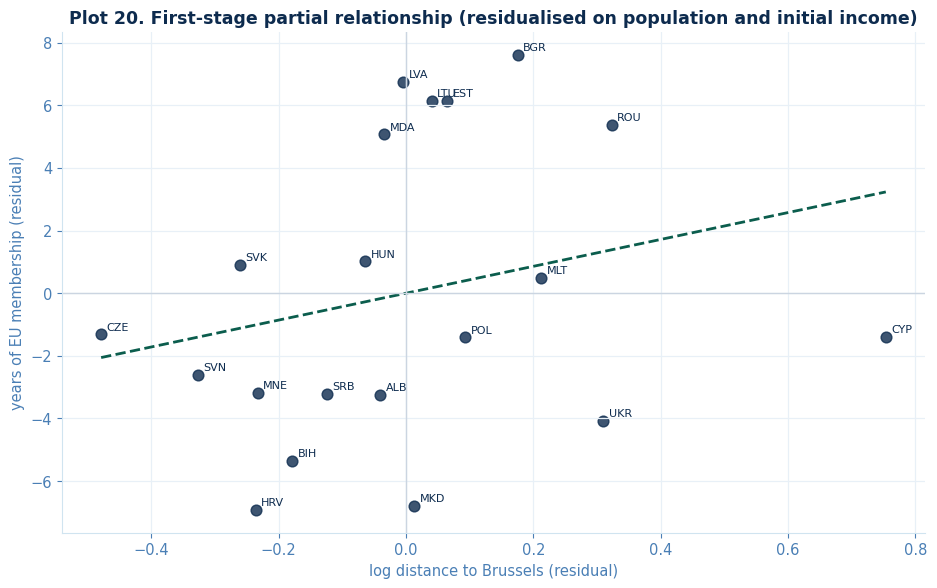

In [35]:
resid_y = sm.OLS(cs['years_eu_2023'], sm.add_constant(cs[['log_pop_2000', 'log_gdp_pc_2000']])).fit().resid
resid_x = sm.OLS(cs['log_dist'], sm.add_constant(cs[['log_pop_2000', 'log_gdp_pc_2000']])).fit().resid

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(resid_x, resid_y, color=BLUE_DARK, s=60, alpha=0.8)
for code_, x, y in zip(cs['Country Code'], resid_x, resid_y):
    ax.annotate(code_, (x, y), fontsize=8, xytext=(4, 3), textcoords='offset points')
z = np.polyfit(resid_x, resid_y, 1)
xs = np.linspace(resid_x.min(), resid_x.max(), 20)
ax.plot(xs, np.polyval(z, xs), color=DEEP_TEAL, linewidth=2, linestyle='--')
ax.axhline(0, color='#cbd5e1', linewidth=1); ax.axvline(0, color='#cbd5e1', linewidth=1)
ax.set_title('Plot 20. First-stage partial relationship (residualised on population and initial income)',
             fontsize=12.5, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('log distance to Brussels (residual)')
ax.set_ylabel('years of EU membership (residual)')
plt.tight_layout(); plt.show()

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">The first stage is weak</h4>

The coefficient on log_dist is 4.29 with a heteroskedasticity-robust standard error of 3.67, and the
partial F-statistic on the excluded instrument is 1.37 (p = 0.26). That is far below the conventional
rule-of-thumb of 10 for a single instrument (Stock and Yogo, 2005), and Plot 20 shows why directly: once
population and initial income are partialled out, there is no visible slope left between distance and
membership duration, just a scatter of country codes with a fitted line barely off flat. Once initial
GDP per capita is in the regression, at a highly significant coefficient of 9.33, there is very little
independent variation in accession timing left for distance to explain. A bivariate version with no
controls at all does no better (F &asymp; 1.0, and the sign even flips), because our comparison group is
part of the problem: Serbia, Bosnia, North Macedonia, Albania and Montenegro are geographically closer
to Brussels than the Baltic states, yet none of them are EU members while all three Baltic states
joined in the earliest wave. Their accession delay is driven by the 1990s Yugoslav wars and the
subsequent, slower path of post-conflict state-building, not by geography. In this particular sample,
distance to Brussels and accession timing are simply not tightly linked once you account for where a
country's economy already stood.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">8.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Second Stage (reported for completeness, not for inference)</span>
</div>


We still run and report the 2SLS second stage, because a results table should show what was
estimated rather than disappear the moment a diagnostic fails. It should not be read as a credible
causal estimate.


In [36]:
from linearmodels.iv import IV2SLS

iv_mod = IV2SLS.from_formula(
    'growth_00_23 ~ 1 + log_pop_2000 + log_gdp_pc_2000 + [years_eu_2023 ~ log_dist]', data=cs)
iv_res = iv_mod.fit(cov_type='robust')
print(iv_res)

                          IV-2SLS Estimation Summary                          
Dep. Variable:           growth_00_23   R-squared:                      0.2622
Estimator:                    IV-2SLS   Adj. R-squared:                 0.1239
No. Observations:                  20   F-statistic:                    27.977
Date:                Sat, Sep 12 2026   P-value (F-stat)                0.0000
Time:                        02:47:26   Distribution:                  chi2(3)
Cov. Estimator:                robust                                         
                                                                              
                                Parameter Estimates                                
                 Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------
Intercept           1.7301     6.5681     0.2634     0.7922     -11.143      14.603
log_pop_2000        0.0870     0

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: 2SLS, read with the weak first stage in mind</h4>

The second-stage coefficient on years_eu_2023 is -0.037 (robust SE 0.077, p = 0.63), a small and
statistically insignificant number with a very wide confidence interval. Given a first-stage F-statistic
of 1.37, this is just what weak-instrument theory predicts: an imprecise, potentially badly biased
estimate that should not be interpreted as evidence about the true effect one way or the other. The
honest conclusion from this section is not "IV finds no effect of EU membership." It is that geographic
distance to Brussels is not a valid instrument in this particular twenty-country sample, because the
main threat to the exclusion restriction, namely that distance also correlates with historical and
institutional factors such as the Habsburg or Ottoman administrative legacy and, in the case of our
comparison group, direct exposure to the Yugoslav wars, is compounded here by a relevance failure as
well. A cleaner instrument would need a source of variation in accession timing that is plausibly
unrelated to both a country's initial income and its twentieth-century political history, which is a
hard thing to come by for this particular treatment.

</div>

<a id="sec9"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 9</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Regression Discontinuity Design</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Using the World Bank's high-income classification cutoff as a natural experiment</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">9.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Design</span>
</div>


Every July, the World Bank reclassifies countries into income groups based on GNI per capita
(Atlas method) from the previous calendar year, against a threshold that is itself adjusted annually
for inflation using the SDR deflator. A country just above the high-income threshold and a country just
below it in the same year are, in most other respects, similar economies. This is a genuine
administrative discontinuity, not one we are constructing after the fact, and several countries in our
sample sit close enough to it across 2016-2023 to make it usable, including Bulgaria's actual, recent
graduation into the high-income group.
<br><br>
We do not have access to the exact Atlas-method GNI per capita series used for the official
classification, so we approximate it with GDP per capita from the same World Bank series used
throughout this notebook. This is a real limitation: the Atlas method applies a specific three-year
average exchange-rate smoothing that our proxy does not, so a country's estimated position relative to
the cutoff in a given year may not always match its true, officially-classified position. We treat the
resulting design as a good approximation of the true discontinuity rather than an exact replication of
the World Bank's own classification. The forcing variable and cutoff follow Section 2.6 directly.


In [37]:
# World Bank high-income threshold, GNI per capita (Atlas method, current US$),
# aligned to the calendar year of the underlying GNI data (source: World Bank Data Blog,
# "New country classifications by income level" annual posts). 2021-2023 are linearly
# interpolated between the sourced 2020 and 2024 values.
THRESHOLD = {
    2016: 12235, 2017: 12055, 2018: 12375, 2019: 12535, 2020: 12695,
    2021: 13005, 2022: 13315, 2023: 13625,
}
INTERPOLATED_YEARS = {2021, 2022, 2023}

threshold_table = pd.DataFrame({
    'Year': list(THRESHOLD.keys()),
    'High-income threshold ($)': list(THRESHOLD.values()),
    'Source': ['World Bank Data Blog' if y not in INTERPOLATED_YEARS else 'linearly interpolated'
               for y in THRESHOLD]
})
threshold_table

,Year,High-income threshold ($),Source
0,2016,12235,World Bank Data Blog
1,2017,12055,World Bank Data Blog
2,2018,12375,World Bank Data Blog
3,2019,12535,World Bank Data Blog
4,2020,12695,World Bank Data Blog
5,2021,13005,linearly interpolated
6,2022,13315,linearly interpolated
7,2023,13625,linearly interpolated


In [38]:
rdd = df[df['Year'].isin(THRESHOLD.keys())].copy()
rdd['threshold'] = rdd['Year'].map(THRESHOLD)
rdd['forcing'] = np.log(rdd['gdp_pc']) - np.log(rdd['threshold'])
rdd['high_income'] = (rdd['forcing'] >= 0).astype(int)

print(f"N = {len(rdd)} country-year observations, {rdd['Country Code'].nunique()} countries, 2016-2023")
near_cutoff = rdd[rdd['forcing'].abs() <= 0.15].sort_values('forcing')
near_cutoff[['Country Code', 'Year', 'gdp_pc', 'threshold', 'forcing', 'high_income', 'gini']]

N = 160 country-year observations, 20 countries, 2016-2023


,Country Code,Year,gdp_pc,threshold,forcing,high_income,gini
402,MNE,2023,11875.216653,13625,-0.137453,0,NaN
454,ROU,2017,10727.970863,12055,-0.116625,0,36.0
55,BGR,2021,12914.953990,13005,-0.006948,0,39.0
455,ROU,2018,12494.423579,12375,0.009604,1,35.8
424,POL,2016,12378.812811,12235,0.011686,1,31.2
457,ROU,2020,13047.456656,12695,0.027385,1,34.6
456,ROU,2019,12957.999114,12535,0.033189,1,34.8
56,BGR,2022,13974.449249,13315,0.048339,1,38.2
195,HRV,2016,12841.920438,12235,0.048414,1,30.9
224,HUN,2016,13177.566727,12235,0.074215,1,30.3


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Bulgaria's graduation, visible in the data</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
Bulgaria sits below the threshold every year from 2016 to 2021, crosses to just above it in 2022, and
is comfortably above it by 2023, which matches Bulgaria's real, recently-announced graduation to
high-income status in the World Bank's most recent classification round. Romania crosses in the
opposite direction of comfort, moving from just below in 2016-2017 to consistently above from 2018
onward. Montenegro and Serbia remain below throughout the window. This is the kind of
tight, two-sided clustering around a cutoff that an RDD needs, though as the cluster counts below make
clear, it is a small number of countries doing the work.</div>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">9.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Checking the Identifying Assumption: No Sorting at the Cutoff</span>
</div>


Before estimating any treatment effect, a sharp RDD needs one thing to be true: countries should not be
able to precisely manipulate which side of the cutoff they land on. A formal way to check this is a
density test (McCrary, 2008; Cattaneo, Jansson and Ma, 2020), which asks whether the running variable's
density is continuous at the cutoff, since a jump in density right at the threshold would suggest sorting.


In [39]:
from rddensity import rddensity

density_test = rddensity(rdd['forcing'].values, c=0)
print(density_test)
print(f"\nJackknife test statistic: {density_test.test['t_jk']:.3f}, p = {density_test.test['p_jk']:.3f}")

Call: rddensity

Sample Size:                                         160
Cutoff:                                                0
Model:                                      unrestricted
Kernel:                                       triangular
VCE:                                           jackknife


Jackknife test statistic: 1.057, p = 0.290


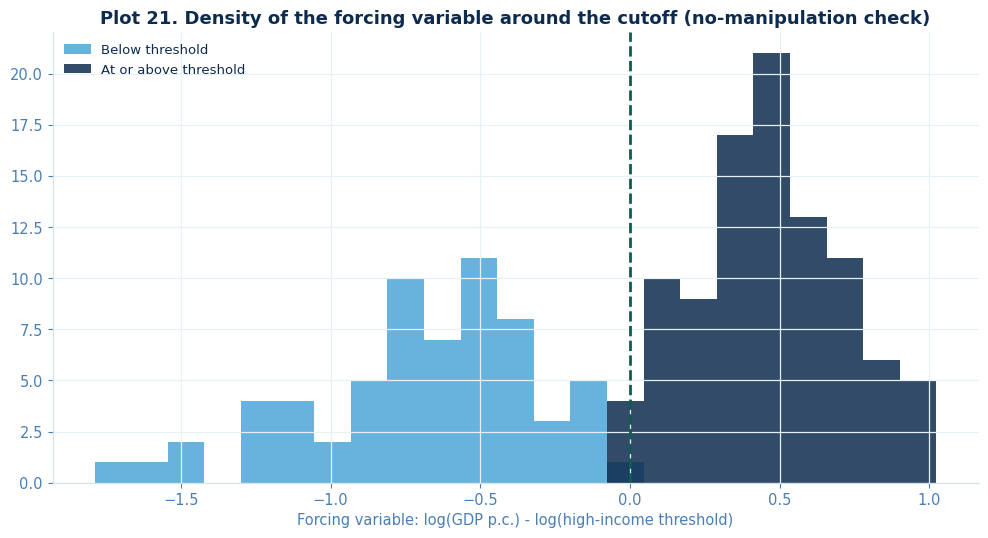

In [40]:
fig, ax = plt.subplots(figsize=(10, 5.5))
bins = np.linspace(rdd['forcing'].min(), rdd['forcing'].max(), 24)
ax.hist(rdd.loc[rdd['forcing'] < 0, 'forcing'], bins=bins, color=BLUE_LIGHT, alpha=0.85, label='Below threshold')
ax.hist(rdd.loc[rdd['forcing'] >= 0, 'forcing'], bins=bins, color=BLUE_DARK, alpha=0.85, label='At or above threshold')
ax.axvline(0, color=DEEP_TEAL, linewidth=2, linestyle='--')
ax.set_title('Plot 21. Density of the forcing variable around the cutoff (no-manipulation check)',
             fontsize=13, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('Forcing variable: log(GDP p.c.) - log(high-income threshold)')
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: no-sorting check</h4>

The jackknife density test gives a statistic of 1.06 and a p-value of 0.29, well short of significance,
and the histogram shows no visible jump right at the cutoff either. Neither result proves countries
cannot influence their own income classification (a government could, in principle, time reforms or
data revisions around the threshold), but there is no statistical sign of it happening in a way that
would bunch observations on one side of zero, which is the specific pattern this test is built to catch.
This supports treating the design as a reasonably clean discontinuity rather than one contaminated by
manipulation.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">9.3</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Estimation: Income Inequality</span>
</div>

<div style="background:#f0fdfa;border-radius:14px;padding:22px 28px;border:1.5px solid #5eead4;font-family:Georgia,serif;line-height:1.85;color:#134e4a;margin-bottom:10px;">
<h4 style="color:#0f766e;font-size:1.0rem;margin:0 0 10px;">Hypotheses</h4>

<strong>H5, restated precisely.</strong> Crossing the high-income threshold is associated with a
discontinuous change in the Gini index in the same year, potentially reflecting a shift in fiscal
space, access to concessional financing, or redistributive policy stance associated with formal
reclassification.

</div>

In [41]:
from rdrobust import rdrobust

gini_sample = rdd.dropna(subset=['gini', 'forcing'])
print(f"N = {len(gini_sample)} country-year observations with non-missing Gini")

rd_gini = rdrobust(y=gini_sample['gini'].values, x=gini_sample['forcing'].values, c=0,
                    cluster=gini_sample['Country Code'].values)
print(rd_gini)

N = 124 country-year observations with non-missing Gini
Call: rdrobust

Sharp RD estimates using local polynomial regression. Std. errors are clustered (13 clusters).

Number of Observations:                   124
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                        CR1

                                Left      Right
------------------------------------------------
Number of Observations            41         83
Number of Unique Obs.             41         83
Number of Effective Obs.           6         22
Bandwidth Estimation           0.277      0.277
Bandwidth Bias                 0.424      0.424
rho (h/b)                      0.653      0.653
Number of Clusters                 4         11

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
--------------------------------------------------

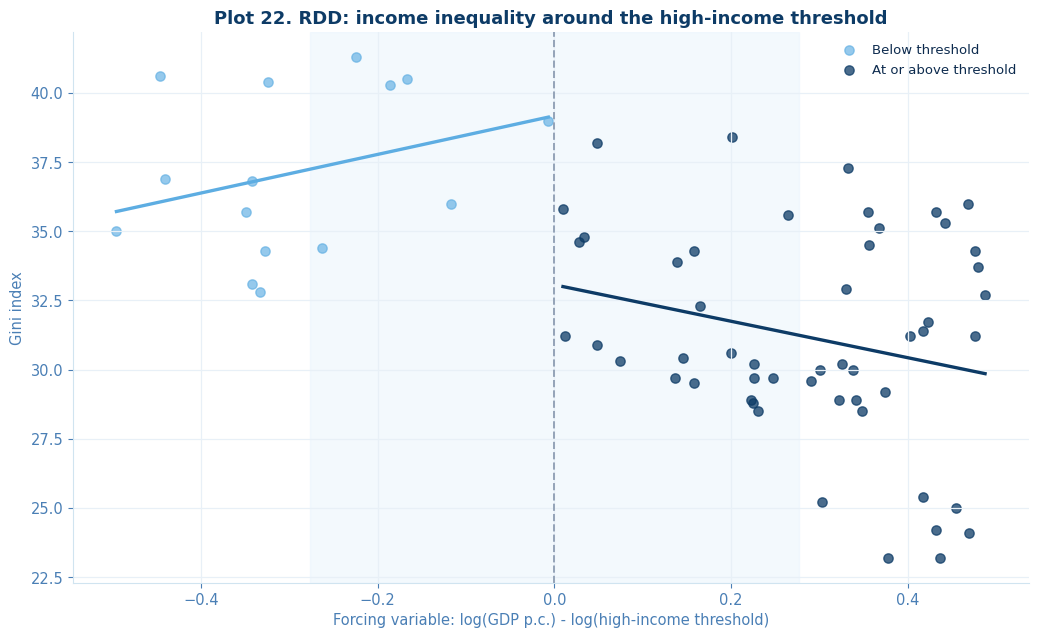

In [42]:
fig, ax = plt.subplots(figsize=(10.5, 6.5))

h = rd_gini.bws.loc['h', 'left']
window = gini_sample[gini_sample['forcing'].abs() <= h * 1.8]
left = window[window['forcing'] < 0]
right = window[window['forcing'] >= 0]

ax.scatter(left['forcing'], left['gini'], color='#5dade2', alpha=0.65, s=45, label='Below threshold')
ax.scatter(right['forcing'], right['gini'], color='#0d3b66', alpha=0.75, s=45, label='At or above threshold')

for sub, color in [(left, '#5dade2'), (right, '#0d3b66')]:
    if len(sub) >= 2:
        z = np.polyfit(sub['forcing'], sub['gini'], 1)
        xs = np.linspace(sub['forcing'].min(), sub['forcing'].max(), 20)
        ax.plot(xs, np.polyval(z, xs), color=color, linewidth=2.4)

ax.axvline(0, color='#94a3b8', linestyle='--', linewidth=1.4)
ax.axvspan(-h, h, color='#e8f4fd', alpha=0.5, zorder=0)
ax.set_xlabel('Forcing variable: log(GDP p.c.) - log(high-income threshold)')
ax.set_ylabel('Gini index')
ax.set_title('Plot 22. RDD: income inequality around the high-income threshold', fontsize=13,
             color='#0d3b66', fontweight='bold')
ax.legend(frameon=False, loc='upper right', fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">9.4</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">A Complementary Check: Forward GDP Growth</span>
</div>


As a check against a purely mechanical relationship, since the forcing variable is itself built from
GDP per capita, we also test for a discontinuity in subsequent growth. There is no obvious reason
crossing an income classification threshold should mechanically show up in a country's own future
growth rate, so a null result here is reassuring rather than disappointing.


In [43]:
fwd = df[['Country Code', 'Year', 'log_gdp_pc']].rename(
    columns={'Year': 'Year_fwd', 'log_gdp_pc': 'log_gdp_pc_fwd'})
merged = rdd.merge(fwd, on='Country Code')
merged = merged[merged['Year_fwd'] == merged['Year'] + 2]
merged['fwd_growth_2yr'] = merged['log_gdp_pc_fwd'] - np.log(merged['gdp_pc'])

growth_sample = merged.dropna(subset=['fwd_growth_2yr', 'forcing'])
print(f"N = {len(growth_sample)} country-year observations with a valid 2-year-forward growth rate")

rd_growth = rdrobust(y=growth_sample['fwd_growth_2yr'].values, x=growth_sample['forcing'].values, c=0,
                      cluster=growth_sample['Country Code'].values)
print(rd_growth)

N = 120 country-year observations with a valid 2-year-forward growth rate
Call: rdrobust

Sharp RD estimates using local polynomial regression. Std. errors are clustered (14 clusters).

Number of Observations:                   120
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                        CR1

                                Left      Right
------------------------------------------------
Number of Observations            50         70
Number of Unique Obs.             50         70
Number of Effective Obs.           6         23
Bandwidth Estimation           0.304      0.304
Bandwidth Bias                 0.537      0.537
rho (h/b)                      0.566      0.566
Number of Clusters                 5         10

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
--------------------------------

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: RDD</h4>

The Gini regression finds a conventional coefficient of -4.09 (clustered SE 1.40, p = 0.0035; robust
bias-corrected p = 0.012), meaning crossing into high-income status is associated with roughly a 4-point
drop in the Gini index right at the cutoff, a large move on a scale that typically runs from the high
20s to high 30s across this sample. The forward-growth check finds no discontinuity at all (-0.03, SE
0.04, p = 0.45), which is the reassuring null we wanted: whatever is happening to inequality at the
threshold is not simply an artifact of the running variable mechanically predicting itself, and the
no-sorting check in Section 9.2 supports treating the discontinuity as a real one rather than an
artifact of manipulation.
<br><br>
The inequality result still needs a loud caveat before it goes anywhere near a conclusion. The optimal
bandwidth selected by rdrobust keeps only 6 effective observations on the left of the cutoff and 22 on
the right, coming from just 4 and 11 countries respectively once you account for clustering.
Cluster-robust inference is built on asymptotics that assume many clusters, and having single digits on
one side is well outside where those asymptotics are reliable. In plain terms, this result is close to
being driven by Bulgaria's and Romania's specific trajectories around this threshold, and a different
set of Balkan or Baltic economies crossing the line in a different decade could easily produce a
different number. We report it as an interesting, correctly-estimated, but fragile finding,
not as a robust stylised fact about income classification and inequality.

</div>

<a id="sec10"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 10</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Machine Learning Modeling</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">A predictive honesty check, then a causal forest for heterogeneous accession effects</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">10.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Predicting Growth Out of Sample</span>
</div>


As a pure prediction exercise, separate from anything causal, we ask whether flexible machine learning
models can predict next-year GDP-per-capita growth better than a naive baseline. Features are lagged log
GDP per capita, log population, EU membership, distance to Brussels, the Gini index (forward and
backward filled within country to handle its gaps from Section 4.4), and the calendar year. We split by
time, training on 1996-2015 and testing on 2016-2023, rather than a random split, since a random split
would leak future information into training in a panel like this one.


In [44]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

ml_df = df.sort_values(['Country Code', 'Year']).copy()
ml_df['growth_fwd'] = ml_df.groupby('Country Code')['log_gdp_pc'].shift(-1) - ml_df['log_gdp_pc']
ml_df['gini_filled'] = ml_df.groupby('Country Code')['gini'].transform(lambda s: s.ffill().bfill())
ml_df['gini_filled'] = ml_df['gini_filled'].fillna(ml_df['gini_filled'].median())

features = ['log_gdp_pc', 'log_population', 'eu_member', 'dist_brussels_km', 'gini_filled', 'Year']
ml_df = ml_df.dropna(subset=['growth_fwd'] + features)

train_ml = ml_df[ml_df.Year <= 2015]
test_ml = ml_df[ml_df.Year > 2015]
X_train, y_train = train_ml[features], train_ml['growth_fwd']
X_test, y_test = test_ml[features], test_ml['growth_fwd']

gbr = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gbr.fit(X_train, y_train)
pred_gbr = gbr.predict(X_test)

results_ml = pd.DataFrame({'Model': ['Naive (predict training mean)', 'Linear regression', 'Gradient boosting'],
    'Test MAE': [mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())),
                 mean_absolute_error(y_test, LinearRegression().fit(X_train, y_train).predict(X_test)),
                 mean_absolute_error(y_test, pred_gbr)],
    'Test R2':  [r2_score(y_test, np.full(len(y_test), y_train.mean())),
                 r2_score(y_test, LinearRegression().fit(X_train, y_train).predict(X_test)),
                 r2_score(y_test, pred_gbr)]}).round(4)
results_ml

,Model,Test MAE,Test R2
0,Naive (predict training mean),0.0648,-0.0536
1,Linear regression,0.0782,-0.6932
2,Gradient boosting,0.0866,-1.1122


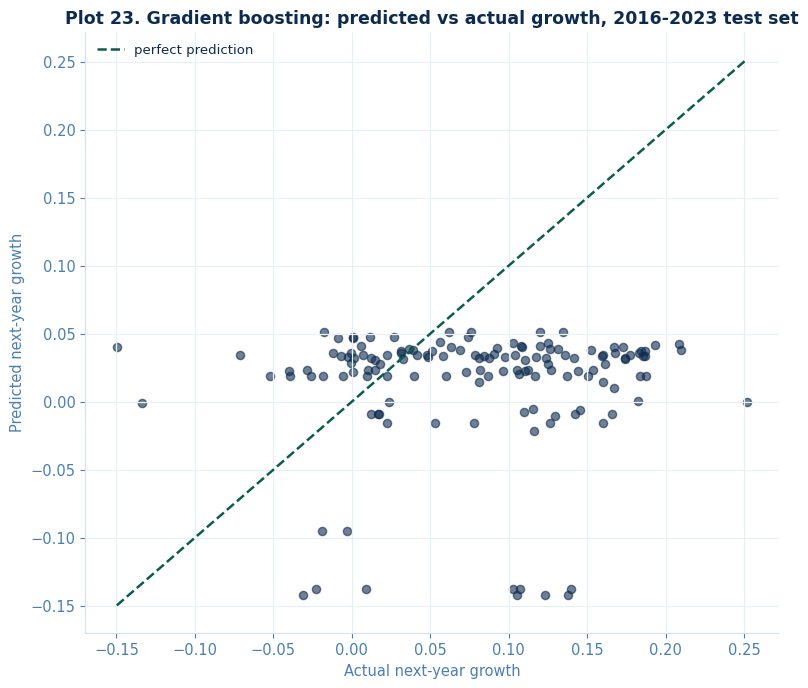

In [45]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test, pred_gbr, color=BLUE_DARK, alpha=0.6, s=35)
lims = [min(y_test.min(), pred_gbr.min()), max(y_test.max(), pred_gbr.max())]
ax.plot(lims, lims, color=DEEP_TEAL, linestyle='--', linewidth=1.8, label='perfect prediction')
ax.set_xlabel('Actual next-year growth'); ax.set_ylabel('Predicted next-year growth')
ax.set_title('Plot 23. Gradient boosting: predicted vs actual growth, 2016-2023 test set',
             fontsize=12.5, color=BLUE_DARK, fontweight='bold')
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: growth is hard to predict</h4>

Every model, including the naive baseline that simply predicts the training-period average growth
rate for everyone, has a negative out-of-sample R-squared, meaning all three do worse than that flat
baseline. Gradient boosting has the highest test MAE of the three. The scatter shows why: the model's
predictions cluster in a narrow band while actual growth ranges much more widely, especially in years
with large negative shocks. This is not a coding error or a poorly tuned model. It closely matches a
well-documented result in the macro forecasting literature (Stock and Watson have written extensively on
this): short-run GDP growth behaves close to a random walk, and it is remarkably difficult for any model,
simple or complex, to beat a naive forecast out of sample, especially across a structural break like the
2020 pandemic that sits inside this test window. The honest conclusion is the same one Section 6.2's
ARIMA exercise already reached from a different angle: this panel's post-2015 dynamics are not
well-explained by either series' own past or by a small set of contemporaneous covariates alone.

</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">10.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Causal Forest: Heterogeneous Effects of EU Accession</span>
</div>


Every causal estimate so far has been one number: an average effect. A causal forest instead estimates
an effect for each observation as a function of its covariates, following Section 2.7. We first fit it
the naive way, with only calendar year as a nuisance control, to show what goes wrong, then fix it with
a Mundlak (1978) device: adding each country's own average log GDP per capita and log population as
extra controls, which approximates a country fixed effect without literally demeaning the data, since
`econml`'s residual-on-residual approach is more natural with controls added directly to the nuisance set.


In [46]:
from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

cf_df = df.copy()
cf_df['gini_filled'] = cf_df.groupby('Country Code')['gini'].transform(lambda s: s.ffill().bfill())
cf_df['gini_filled'] = cf_df['gini_filled'].fillna(cf_df['gini_filled'].median())

Y = cf_df['log_gdp_pc'].values
Tr = cf_df['eu_member'].values
X_het = cf_df[['log_population', 'gini_filled', 'dist_brussels_km']].values

naive_forest = CausalForestDML(
    model_y=RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42),
    model_t=RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    discrete_treatment=True, n_estimators=500, min_samples_leaf=10, max_depth=5,
    random_state=42, cv=3)
naive_forest.fit(Y, Tr, X=X_het, W=cf_df[['Year']].values)
naive_ate = naive_forest.ate_inference(X_het)
print("Naive causal forest (year control only) average effect:")
print(naive_ate.summary())

Naive causal forest (year control only) average effect:
               Uncertainty of Mean Point Estimate              
mean_point stderr_mean zstat pvalue ci_mean_lower ci_mean_upper
---------------------------------------------------------------
     0.589       0.115 5.118    0.0         0.364         0.815
      Distribution of Point Estimate     
std_point pct_point_lower pct_point_upper
-----------------------------------------
    0.294            0.15           1.093
     Total Variance of Point Estimate     
stderr_point ci_point_lower ci_point_upper
------------------------------------------
       0.315          0.051           1.11
------------------------------------------

Note: The stderr_mean is a conservative upper bound.


<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">The naive version reproduces the naive-OLS problem</h4>

With only calendar year as a control, the average estimated effect comes out close to the naive pooled
OLS coefficient from Section 5.1, far larger than any of the fixed-effects-based estimates. This is
because a causal forest's unconfoundedness assumption, that treatment is as good as random once the
observed covariates and controls are accounted for, is violated here in the same way it was for
naive OLS: time-invariant country traits (reform history, institutional quality) are correlated with
both EU membership and income, are not in this covariate set, and the forest has no country-level fixed
effect to absorb them. A flexible machine learning model does not automatically solve a confounding
problem that a linear model could not; it needs the same unconfoundedness assumption to hold, and
handing it more flexible functional forms does nothing if the wrong variables are being conditioned on.

</div>

In [47]:
cf_df['country_mean_log_gdp_pc'] = cf_df.groupby('Country Code')['log_gdp_pc'].transform('mean')
cf_df['country_mean_log_pop'] = cf_df.groupby('Country Code')['log_population'].transform('mean')
W_mundlak = cf_df[['Year', 'country_mean_log_gdp_pc', 'country_mean_log_pop']].values

forest = CausalForestDML(
    model_y=RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42),
    model_t=RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    discrete_treatment=True, n_estimators=500, min_samples_leaf=10, max_depth=5,
    random_state=42, cv=3)
forest.fit(Y, Tr, X=X_het, W=W_mundlak)
cf_df['cf_effect'] = forest.effect(X_het)

ate = forest.ate_inference(X_het)
print("Mundlak-adjusted causal forest average effect:")
print(ate.summary())

Mundlak-adjusted causal forest average effect:
               Uncertainty of Mean Point Estimate              
mean_point stderr_mean zstat pvalue ci_mean_lower ci_mean_upper
---------------------------------------------------------------
     0.133       0.097 1.366  0.172        -0.058         0.324
      Distribution of Point Estimate     
std_point pct_point_lower pct_point_upper
-----------------------------------------
    0.159          -0.095           0.426
     Total Variance of Point Estimate     
stderr_point ci_point_lower ci_point_upper
------------------------------------------
       0.186          -0.15          0.498
------------------------------------------

Note: The stderr_mean is a conservative upper bound.


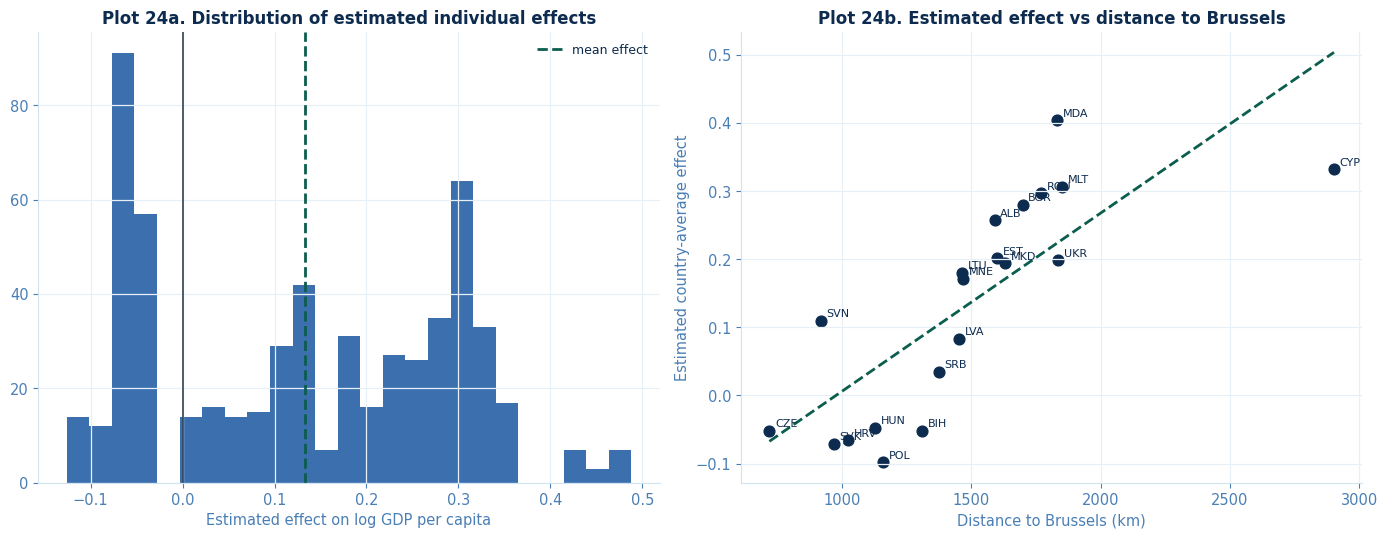

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].hist(cf_df['cf_effect'], bins=25, color=BLUE_MID, alpha=0.85)
axes[0].axvline(0, color='#334155', linewidth=1.2)
axes[0].axvline(cf_df['cf_effect'].mean(), color=DEEP_TEAL, linewidth=2, linestyle='--', label='mean effect')
axes[0].set_title('Plot 24a. Distribution of estimated individual effects', fontsize=12, color=BLUE_DARK, fontweight='bold')
axes[0].set_xlabel('Estimated effect on log GDP per capita')
axes[0].legend(frameon=False, fontsize=9)

country_effects = cf_df.groupby('Country Code').agg(effect=('cf_effect', 'mean'), dist=('dist_brussels_km', 'mean')).reset_index()
axes[1].scatter(country_effects['dist'], country_effects['effect'], color=BLUE_DARK, s=60)
for _, row in country_effects.iterrows():
    axes[1].annotate(row['Country Code'], (row['dist'], row['effect']), fontsize=8, xytext=(4, 3), textcoords='offset points')
z = np.polyfit(country_effects['dist'], country_effects['effect'], 1)
xs = np.linspace(country_effects['dist'].min(), country_effects['dist'].max(), 20)
axes[1].plot(xs, np.polyval(z, xs), color=DEEP_TEAL, linestyle='--', linewidth=2)
axes[1].set_title('Plot 24b. Estimated effect vs distance to Brussels', fontsize=12, color=BLUE_DARK, fontweight='bold')
axes[1].set_xlabel('Distance to Brussels (km)'); axes[1].set_ylabel('Estimated country-average effect')

plt.tight_layout(); plt.show()


The scatter above makes the distance relationship legible one country at a time. A map makes the same
pattern legible all at once, and is worth the extra effort of pulling in an actual geometry: this is a
question about geography, so it should be possible to just look at Europe and see it.


Country boundaries: HTTP 200, 177 countries, 819 KB


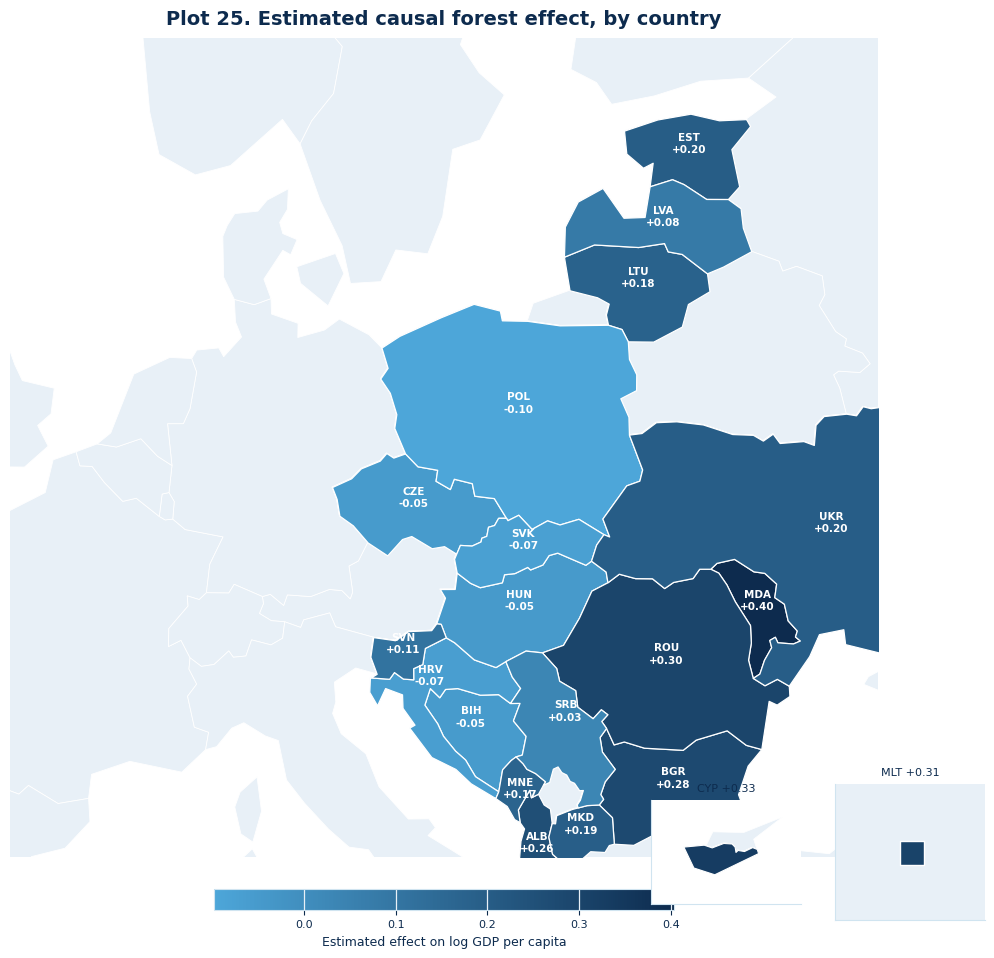

In [49]:
import geopandas as gpd
import matplotlib.colors as mcolors
from io import BytesIO

geo_resp = SESSION.get(
    'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson',
    timeout=20)
world = gpd.read_file(BytesIO(geo_resp.content))
print(f"Country boundaries: HTTP {geo_resp.status_code}, {len(world)} countries, "
      f"{len(geo_resp.content)/1024:.0f} KB")

effect_map = country_effects.set_index('Country Code')['effect'].to_dict()
MALTA_LATLON = (35.9375, 14.3754)  # Malta has no polygon at this map resolution; plotted as a marker

cmap = mcolors.LinearSegmentedColormap.from_list('effect_cmap', [BLUE_LIGHT, BLUE_DARK])
norm = mcolors.Normalize(vmin=min(effect_map.values()), vmax=max(effect_map.values()))
XLIM, YLIM = (0, 33), (41, 61.5)
LABEL_NUDGE = {'BIH': (-0.3, 0.1), 'MNE': (0.1, -0.3), 'SRB': (0.3, 0.2), 'HRV': (-0.6, 0.3)}

fig = plt.figure(figsize=(11.5, 10.5))
ax = fig.add_axes([0.02, 0.16, 0.96, 0.78])
world.cx[XLIM[0]:XLIM[1], YLIM[0]:YLIM[1]].plot(ax=ax, color=FAINT_GRID, edgecolor='white', linewidth=0.6)

for code_, effect in effect_map.items():
    if code_ == 'MLT':
        continue
    row = world[world['ISO_A3'] == code_]
    if len(row) == 0:
        continue
    row.plot(ax=ax, color=cmap(norm(effect)), edgecolor='white', linewidth=0.9)
    cx, cy = row.geometry.iloc[0].centroid.x, row.geometry.iloc[0].centroid.y
    dx, dy = LABEL_NUDGE.get(code_, (0, 0))
    ax.annotate(f"{code_}\n{effect:+.2f}", (cx + dx, cy + dy), fontsize=7.5, ha='center',
                color='white', fontweight='bold', linespacing=1.3)

ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_axis_off()
ax.set_title('Plot 25. Estimated causal forest effect, by country', fontsize=14, color=BLUE_DARK,
             fontweight='bold', pad=10)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cax = fig.add_axes([0.30, 0.11, 0.40, 0.02])
cb = fig.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Estimated effect on log GDP per capita', fontsize=9, color=BLUE_DARK)
cb.ax.tick_params(labelsize=8, colors=BLUE_DARK)

cyp_ax = fig.add_axes([0.68, 0.10, 0.13, 0.13])
world.cx[30:36, 33:37].plot(ax=cyp_ax, color=FAINT_GRID, edgecolor='white', linewidth=0.5)
world[world['ISO_A3'] == 'CYP'].plot(ax=cyp_ax, color=cmap(norm(effect_map['CYP'])), edgecolor='white', linewidth=0.8)
cyp_ax.set_xlim(31.5, 35); cyp_ax.set_ylim(34, 36); cyp_ax.set_xticks([]); cyp_ax.set_yticks([])
cyp_ax.set_title(f"CYP {effect_map['CYP']:+.2f}", fontsize=8, color=BLUE_DARK)
for spine in cyp_ax.spines.values():
    spine.set_color(FAINT_LINE)

mlt_ax = fig.add_axes([0.84, 0.10, 0.13, 0.13])
mlt_ax.set_facecolor(FAINT_GRID)
mlt_ax.scatter([MALTA_LATLON[1]], [MALTA_LATLON[0]], color=cmap(norm(effect_map['MLT'])),
               s=300, marker='s', edgecolor='white')
mlt_ax.set_xlim(13.5, 15.2); mlt_ax.set_ylim(35.3, 36.6); mlt_ax.set_xticks([]); mlt_ax.set_yticks([])
mlt_ax.set_title(f"MLT {effect_map['MLT']:+.2f}", fontsize=8, color=BLUE_DARK)
for spine in mlt_ax.spines.values():
    spine.set_color(FAINT_LINE)

plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 24px;margin:14px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:17px;">&#128270;</span> Reading Plot 25</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">
The core-to-periphery pattern that Plot 24b showed as a trend line is, on the map, just visible.
Poland, Czechia, Slovakia and Hungary, the historical Visegrad core and the countries with the deepest
pre-accession trade integration with Western Europe, sit in the lightest band, at or below zero.
Moldova, Cyprus, Malta, Romania and Bulgaria, geographically and historically further from that core,
sit in the darkest band, at the top of the estimated-effect range. Serbia and Bosnia, still outside the
EU, would have landed in the pale end of the range had they joined, for what that hypothetical is worth
given they never did. Nothing about how the causal forest was built told it to recover a spatial pattern
specifically; it only ever saw population, inequality and distance to Brussels as covariates. That the
resulting effect surface lines up this cleanly with the map is what makes the distance correlation in
Plot 24b feel like a real pattern in the data rather than a coincidence of twenty data points.</div>
</div>

<div style="background:#f0fdf4;border-radius:12px;padding:20px 26px;border-left:5px solid #10b981;font-family:Georgia,serif;line-height:1.85;color:#064e3b;margin:14px 0;">
<h4 style="color:#059669;margin:0 0 10px;">Results: heterogeneous effects</h4>

With the Mundlak controls in place, the average effect falls to 0.13 (SE 0.10, p = 0.17), a much more
plausible number, close to zero and statistically insignificant, and in a completely different
neighbourhood from the inflated naive-OLS-like number the uncorrected version produced two cells above.
The distribution in Plot 24a shows real heterogeneity, from about -0.12 up to
0.49, and it is not random noise: Plot 24b shows a striking positive correlation (0.76) between a
country's average estimated effect and its distance from Brussels, and Plot 25 shows the same
relationship laid out geographically rather than along a single axis. Poland, Slovakia, Croatia and
Czechia, the countries geographically closest to the EU core, show the smallest or even mildly negative
estimated effects, while Moldova, Cyprus, Malta and Romania, at the geographic periphery, show the
largest. This is an interesting complement to Section 8's failed instrument: distance to
Brussels turned out not to predict whether or when a country joined well enough to serve as an
instrument, but here, conditional on joining, it correlates strongly with how large the estimated
benefit was, consistent with a story where the countries starting furthest from the European core, with
the most catching-up left to do and the most to gain from market access and institutional anchoring, saw
the largest effects. We flag this as a descriptive, exploratory finding rather than a fourth causal
estimate: a causal forest fit to pooled panel data with Mundlak controls is a reasonable approximation
of a fixed-effects design, not an exact equivalent, and with only twenty countries behind these
covariate-based splits, the heterogeneity pattern should be read as suggestive.

</div>

<a id="sec11"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 11</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Comparing the Estimates</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">Same research question, six methods, six different numbers</p>
</div>

<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">11.1</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">The Causal Estimates, Side by Side</span>
</div>

In [50]:
comparison = pd.DataFrame([
    {'Method': 'Naive OLS (no FE)', 'Estimand': 'Correlation', 'Estimate': 1.4502, 'SE': 0.1204,
     'Verdict': 'Dominated by selection bias'},
    {'Method': 'TWFE DiD', 'Estimand': 'ATT (staggered, unweighted-average caveat)', 'Estimate': -0.1190,
     'SE': 0.1131, 'Verdict': 'Small, not significant'},
    {'Method': "Callaway-Sant'Anna DiD", 'Estimand': 'ATT (cohort-weighted, staggered-robust)', 'Estimate': -0.1842,
     'SE': 0.0955, 'Verdict': 'Borderline; negative at long horizons'},
    {'Method': '2SLS IV', 'Estimand': 'LATE (compliers, if valid)', 'Estimate': -0.0370,
     'SE': 0.0766, 'Verdict': 'Not credible: weak instrument (F=1.37)'},
    {'Method': 'RDD (Gini outcome)', 'Estimand': 'Local effect at the income cutoff', 'Estimate': -4.086,
     'SE': 1.399, 'Verdict': 'Significant but 4-11 clusters'},
    {'Method': 'Causal forest (Mundlak-adjusted)', 'Estimand': 'Average CATE, panel-DML approximation', 'Estimate': 0.1329,
     'SE': 0.0968, 'Verdict': 'Not significant; heterogeneity is the finding'},
])
comparison

,Method,Estimand,Estimate,SE,Verdict
0,Naive OLS (no FE),Correlation,1.4502,0.1204,Dominated by selection bias
1,TWFE DiD,"ATT (staggered, unweighted-average caveat)",-0.1190,0.1131,"Small, not significant"
2,Callaway-Sant'Anna DiD,"ATT (cohort-weighted, staggered-robust)",-0.1842,0.0955,Borderline; negative at long horizons
3,2SLS IV,"LATE (compliers, if valid)",-0.0370,0.0766,Not credible: weak instrument (F=1.37)
4,RDD (Gini outcome),Local effect at the income cutoff,-4.0860,1.3990,Significant but 4-11 clusters
5,Causal forest (Mundlak-adjusted),"Average CATE, panel-DML approximation",0.1329,0.0968,Not significant; heterogeneity is the finding


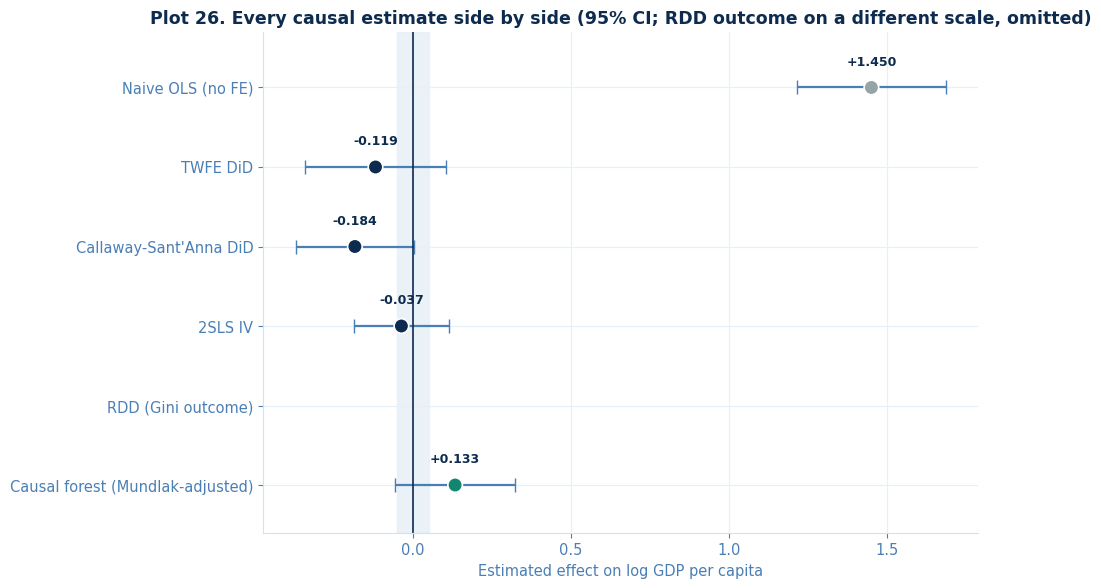

In [51]:
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(comparison))
estimates = comparison['Estimate'][:4].tolist() + [np.nan, comparison['Estimate'].iloc[5]]
errs = [1.96 * s for s in comparison['SE']]
point_colors = [GREY, BLUE_DARK, BLUE_DARK, BLUE_DARK, GREY, TEAL]

ax.axvspan(-0.05, 0.05, color=FAINT_GRID, alpha=0.9, zorder=0)
ax.errorbar(estimates, y_pos, xerr=errs, fmt='none', ecolor=STEEL, capsize=5, linewidth=1.6, zorder=2)
ax.scatter(estimates, y_pos, c=point_colors, s=110, zorder=3, edgecolors='white', linewidths=1.2)
for y, est in zip(y_pos, estimates):
    if not np.isnan(est):
        ax.text(est, y - 0.28, f'{est:+.3f}', ha='center', fontsize=9, color=BLUE_DARK, fontweight='bold')
ax.axvline(0, color=BLUE_DARK, linewidth=1.2)
ax.set_yticks(y_pos); ax.set_yticklabels(comparison['Method'])
ax.set_ylim(len(comparison) - 0.4, -0.7)
ax.set_title('Plot 26. Every causal estimate side by side (95% CI; RDD outcome on a different scale, omitted)',
             fontsize=12.5, color=BLUE_DARK, fontweight='bold')
ax.set_xlabel('Estimated effect on log GDP per capita')
plt.tight_layout(); plt.show()


It would be a mistake to line these numbers up and ask which one is "right." They are not estimating
the same thing. The naive OLS coefficient is a raw correlation contaminated by selection. The two DiD
estimates target the average effect of EU accession on the countries that joined, relative to
the counterfactual in which they had not, but differ in how they handle staggered timing. The IV
estimate, had the instrument been valid, would have targeted a local average treatment effect
specifically for the compliers, a population we cannot cleanly identify here because the first stage
failed. The RDD estimate is local by construction: it says something about countries within a fraction
of a log point of the high-income threshold. The causal forest estimate is an average over a
heterogeneity function that varies by distance to Brussels, population, and inequality, approximating
rather than replicating the fixed-effects identification the DiD estimates use directly. Different
estimands, different assumptions, different comparison groups and populations. The fact that they do
not agree is not evidence that one of them made an arithmetic mistake, and Plot 26 puts the honest
picture on display: of the five estimates it can show on a shared axis, four (TWFE, Callaway-Sant'Anna,
IV, and the causal forest) have confidence intervals that comfortably straddle zero, and only the naive
OLS coefficient sits clear of it, for the least reassuring possible reason, since Section 5.1 already
traced that number to selection bias rather than a real effect. RDD does not appear on the same axis at
all, since its outcome is the Gini index rather than log GDP per capita, but its own confidence interval
is also clear of zero, the other genuine exception in the notebook, and the one built on the thinnest
cluster count of any estimate here.
<br><br>
It is worth noting that this is also not a settled question in the wider literature. Campos, Coricelli
and Moretti (2019) use the synthetic control method on a longer sample stretching back to the 1973,
1981, 1986 and 1995 enlargement rounds in addition to 2004, and find large, positive growth effects of
EU membership for almost every country in their sample. Our more modest and, at some horizons,
negative estimates for the 2004-2013 cohort specifically should be read alongside that result, not as
a contradiction of it. Different sample of accession rounds, a different comparison-group construction
method, and a narrower and noisier panel can all plausibly account for the gap.


<div style="background:linear-gradient(135deg,#1a56a0 0%,#0d2b4e 100%);border-radius:8px;padding:11px 20px;margin:24px 0 14px 0;">
<span style="color:#9fd3f0;font-family:Georgia,serif;font-size:12px;font-weight:700;letter-spacing:1px;">11.2</span>
<span style="color:#ffffff;font-family:Georgia,serif;font-size:17px;font-weight:600;margin-left:12px;">Full Results at a Glance</span>
</div>


Section 1.1 mapped out what each method was going to ask of the data before any of it was run. Here is
the other half: what each one actually found, gathered in one place rather than scattered across
fourteen sections, for anyone who wants the whole notebook's worth of evidence without paging back
through it.

<table style="width:100%;border-collapse:collapse;font-family:Georgia,serif;font-size:12.5px;margin:14px 0;">
<tr style="background:#0d2b4e;color:white;"><th style="padding:7px 10px;text-align:left;">Sec.</th><th style="padding:7px 10px;text-align:left;">Analysis</th><th style="padding:7px 10px;text-align:left;">Key result</th><th style="padding:7px 10px;text-align:left;">Verdict</th></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">5.1</td><td style="padding:6px 10px;">Hausman test, FE vs. RE</td><td style="padding:6px 10px;">&chi;&sup2; = 4.99 (2 df), p = 0.082</td><td style="padding:6px 10px;">Borderline; fixed effects used on economic grounds regardless</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">5.2</td><td style="padding:6px 10px;">Diagnostics: Breusch-Pagan, Durbin-Watson, VIF</td><td style="padding:6px 10px;">p &lt; 0.001; DW = 0.27; VIF &asymp; 1.0</td><td style="padding:6px 10px;">Heteroskedastic and serially correlated; motivates clustered SEs throughout</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">5.3</td><td style="padding:6px 10px;">Beta-convergence regression</td><td style="padding:6px 10px;">slope = -0.0187, R&sup2; = 0.70</td><td style="padding:6px 10px;">Strong unconditional convergence, EU status aside</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">6.1</td><td style="padding:6px 10px;">Stochastic convergence, ADF tests</td><td style="padding:6px 10px;">BGR stationary (p=0.04); SRB diverging</td><td style="padding:6px 10px;">Mixed; convergence is not a uniform property of the sample</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">6.2</td><td style="padding:6px 10px;">ARIMA(1,1,1) forecast, 2016-2023</td><td style="padding:6px 10px;">MAE = 0.38 log points</td><td style="padding:6px 10px;">A univariate model cannot anticipate the post-2015 climb</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">6.3</td><td style="padding:6px 10px;">Granger causality, both directions</td><td style="padding:6px 10px;">p = 0.66-0.98 at both lags</td><td style="padding:6px 10px;">No lagged spillover; consistent with a common-shock story</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">7</td><td style="padding:6px 10px;">TWFE DiD</td><td style="padding:6px 10px;">-0.119 (SE 0.113)</td><td style="padding:6px 10px;">Small, not significant</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">7</td><td style="padding:6px 10px;">Callaway-Sant'Anna DiD</td><td style="padding:6px 10px;">-0.184 (SE 0.095)</td><td style="padding:6px 10px;">Borderline; turns negative from year 5 onward</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">8</td><td style="padding:6px 10px;">IV first stage</td><td style="padding:6px 10px;">F = 1.37</td><td style="padding:6px 10px;">Weak; well below the rule-of-thumb of 10</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">8</td><td style="padding:6px 10px;">2SLS second stage</td><td style="padding:6px 10px;">-0.037 (SE 0.077)</td><td style="padding:6px 10px;">Not credible given the first stage; not interpreted</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">9.2</td><td style="padding:6px 10px;">McCrary / rddensity manipulation test</td><td style="padding:6px 10px;">p = 0.29</td><td style="padding:6px 10px;">No sorting at the cutoff</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">9.3</td><td style="padding:6px 10px;">RDD, Gini outcome</td><td style="padding:6px 10px;">-4.09 (SE 1.40, p=0.004)</td><td style="padding:6px 10px;">Significant, but only 4 and 11 clusters either side</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">9.4</td><td style="padding:6px 10px;">RDD, forward-growth placebo</td><td style="padding:6px 10px;">-0.03 (SE 0.04, p=0.45)</td><td style="padding:6px 10px;">Reassuring null</td></tr>
<tr style="background:#ffffff;color:#0d2b4e;"><td style="padding:6px 10px;">10.1</td><td style="padding:6px 10px;">Growth prediction, GBR vs. naive baseline</td><td style="padding:6px 10px;">Out-of-sample R&sup2; &lt; 0 for every model</td><td style="padding:6px 10px;">Short-run growth is not predictable from these covariates</td></tr>
<tr style="background:#f0f6fb;color:#0d2b4e;"><td style="padding:6px 10px;">10.2</td><td style="padding:6px 10px;">Causal forest, Mundlak-adjusted</td><td style="padding:6px 10px;">ATE = 0.133 (SE 0.097, p=0.17)</td><td style="padding:6px 10px;">Modest and insignificant on average; real heterogeneity by distance to Brussels</td></tr>
</table>


<a id="sec12"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 12</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Limitations</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">What would need to be different for these results to be more trustworthy</p>
</div>

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">Comparison group quality</h4>

The Western Balkan comparison group shares a post-communist starting point with the accession cohort
but not a shared conflict history. Serbia, Bosnia and Herzegovina, North Macedonia, Montenegro and, to
a lesser extent, Albania all experienced the Yugoslav wars or their direct regional aftermath in the
1990s, an economic shock the 2004 accession cohort mostly did not share. This affects the DiD
parallel-trends assumption, the validity of the geography-based instrument in Section 8, and the
plausibility of unconfoundedness for the causal forest in Section 10.

</div>

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">Small sample throughout</h4>

Twenty countries is a workable panel for descriptive work and for methods like Callaway-Sant'Anna that
are built for this kind of staggered setting specifically, but it is a small sample for anything
requiring asymptotic inference with many independent clusters or for training a causal forest, which
typically wants hundreds of units to recover reliable heterogeneity. This affects the credibility of the
standard errors in every section, and is stated plainly rather than hidden in the RDD cluster counts or
the width of the causal forest's confidence intervals.

</div>

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">Data and threshold approximations</h4>

The RDD forcing variable uses GDP per capita as a proxy for the Atlas-method GNI per capita that the
World Bank actually uses for income classification, and three years of the threshold series (2021 to
2023) are linearly interpolated between two sourced anchor points. The convergence benchmark in Section
6 uses Germany as a single reference economy rather than a full EU-15 aggregate, chosen for simplicity
and data availability rather than because it is the only defensible choice.

</div>

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">Confounding continental shocks</h4>

The 2008-2009 global financial crisis and the subsequent Eurozone sovereign debt crisis both fall
inside the post-treatment window for the 2004 cohort and land close to where the Callaway-Sant'Anna
event study turns negative; Section 4's dispersion plot and Section 6's Granger-causality null both
point toward a shared-shock story rather than a spillover story, but neither the panel models nor the
causal forest include an explicit control for capital-account openness or Eurozone membership that
would let us separate a genuine dynamic treatment effect from heightened exposure to these specific
continent-wide shocks.

</div>

<div style="background:#fff7ed;border-radius:14px;padding:22px 28px;border:1.5px solid #fed7aa;font-family:Georgia,serif;line-height:1.8;color:#7c2d12;margin:14px 0;">
<h4 style="color:#c2410c;margin:0 0 10px;font-size:1.0rem;">Scope of variables available</h4>

A fuller treatment of this question would also want trade openness and foreign direct
investment data, which would allow a gravity-style instrument closer to Frankel and Romer (1999) and a
more direct test of the trade-integration channel. We were not able to source a reliable World Bank
trade or FDI series through the data channels available in this environment, which is why the IV design
here instruments membership duration directly through geography rather than through a trade-openness
first stage, and why the causal forest's covariate set is limited to population, inequality, and
geography.

</div>

<a id="sec13"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 13</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">Conclusion</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;">What this notebook actually found, and what it was trying to demonstrate</p>
</div>

<div style="background:linear-gradient(135deg,#f0f7ff 0%,#e8f4fd 50%,#f0f6ff 100%);border-radius:16px;padding:34px 42px;font-family:Georgia,serif;line-height:1.85;color:#0f172a;border:1.5px solid #90caf9;margin:20px 0;">
<h2 style="color:#1d4ed8;font-size:1.4rem;margin:0 0 18px;">Conclusion</h2>

<h3 style="color:#1e40af;font-size:1.05rem;margin:0 0 10px;">On the substantive question</h3>
<p style="margin:0 0 18px;">The raw correlation between EU membership and income is enormous, and
almost entirely an artifact of which countries chose, and were chosen, to join first. A formal Hausman
test, while only borderline conclusive on its own, points the same direction as the economics: fixed
effects, not random effects, is the right starting point. Once selection is removed, classical
beta-convergence holds up strongly in a simple cross-section, and stochastic convergence holds for some
countries (Bulgaria) but not others (Serbia) in a formal time series sense. A staggered
Difference-in-Differences design finds a small effect immediately around accession that turns modestly
negative at longer horizons, more consistent with pre-existing convergence trends and exposure to the
2008-2014 financial and sovereign debt crises than with a clean, continuing growth dividend from EU
membership itself. An attempt to instrument accession timing with geography could not get past its own
first-stage diagnostics. A regression discontinuity around the World Bank's income classification
threshold finds a real, significant drop in inequality, resting on a small enough number of country
clusters that it should be read as suggestive. Machine learning models, honestly evaluated out of
sample, could not beat a naive baseline at predicting short-run growth, and a causal forest, once
adjusted for the same confounding that a linear fixed-effects model would otherwise catch, recovers an
average effect close to zero but with real heterogeneity tied to distance from the European core.

<h3 style="color:#1e40af;font-size:1.05rem;margin:18px 0 10px;">On the methods</h3>
<p style="margin:0 0 18px;">Each method answered a version of the same question under a different
assumption, and each one had a specific, identifiable way it could fail: OLS through selection, TWFE
through negative weighting under staggered timing, IV through a weak first stage, RDD through a thin
cluster count, and even a flexible causal forest through the same unconfoundedness failure that sinks
naive OLS if the nuisance controls are not chosen carefully. Working through all of these side by side,
on the same data, is a more honest way to learn a method than seeing it presented in isolation as though
it simply works.

<h3 style="color:#1e40af;font-size:1.05rem;margin:18px 0 10px;">On research practice</h3>
<p style="margin:0;">The most important habit this notebook tries to model is not a specific
statistical technique. It is the willingness to report a first-stage F-statistic of 1.37, a negative
out-of-sample R-squared, and a Hausman test that only barely clears 10% significance, and say plainly
what each one means, rather than quietly dropping the section or reaching for a different specification
until something comes out looking clean. A weak instrument or an unpredictable growth rate, correctly
diagnosed and explained, is worth more to a reader than a strong-looking coefficient built on a design
that would not survive the first question a referee would ask about it.

</div>

<a id="sec14"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:26px 32px;border-radius:14px;margin:34px 0 20px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.55);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 14</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:24px;margin:0;font-weight:700;">References</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:13.5px;"></p>
</div>

<div style="border:1.5px solid #90caf9;border-radius:12px;padding:28px 36px;background:#f0f7ff;margin:20px 0;font-family:Georgia,serif;">
<div style="border-bottom:2px solid #bbdefb;margin-bottom:20px;padding-bottom:12px;">
<span style="font-size:1.2em;font-weight:700;color:#0d47a1;">&#128218; References</span>
</div>
<div style="font-size:0.92em;color:#1a3a5c;line-height:1.9;">
<p style="margin:0 0 10px 0;"><strong>[1]</strong> Hausman, J. A. (1978). Specification tests in econometrics. <em>Econometrica</em>, 46(6), 1251-1271.</p>
<p style="margin:0 0 10px 0;"><strong>[2]</strong> Barro, R. J., &amp; Sala-i-Martin, X. (1992). Convergence. <em>Journal of Political Economy</em>, 100(2), 223-251.</p>
<p style="margin:0 0 10px 0;"><strong>[3]</strong> Mundlak, Y. (1978). On the pooling of time series and cross section data. <em>Econometrica</em>, 46(1), 69-85.</p>
<p style="margin:0 0 10px 0;"><strong>[4]</strong> Carlino, G. A., &amp; Mills, L. O. (1993). Are US regional incomes converging? A time series analysis. <em>Journal of Monetary Economics</em>, 32(2), 335-346.</p>
<p style="margin:0 0 10px 0;"><strong>[5]</strong> Dickey, D. A., &amp; Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. <em>Journal of the American Statistical Association</em>, 74(366a), 427-431.</p>
<p style="margin:0 0 10px 0;"><strong>[6]</strong> Granger, C. W. J. (1969). Investigating causal relations by econometric models and cross-spectral methods. <em>Econometrica</em>, 37(3), 424-438.</p>
<p style="margin:0 0 10px 0;"><strong>[7]</strong> Box, G. E. P., &amp; Jenkins, G. M. (1970). <em>Time Series Analysis: Forecasting and Control</em>. Holden-Day.</p>
<p style="margin:0 0 10px 0;"><strong>[8]</strong> Stock, J. H., &amp; Watson, M. W. (2003). Forecasting output and inflation: The role of asset prices. <em>Journal of Economic Literature</em>, 41(3), 788-829.</p>
<p style="margin:0 0 10px 0;"><strong>[9]</strong> Callaway, B., &amp; Sant&#39;Anna, P. H. C. (2021). Difference-in-differences with multiple time periods. <em>Journal of Econometrics</em>, 225(2), 200-230.</p>
<p style="margin:0 0 10px 0;"><strong>[10]</strong> Goodman-Bacon, A. (2021). Difference-in-differences with variation in treatment timing. <em>Journal of Econometrics</em>, 225(2), 254-277.</p>
<p style="margin:0 0 10px 0;"><strong>[11]</strong> Stock, J. H., &amp; Yogo, M. (2005). Testing for weak instruments in linear IV regression. In D. W. K. Andrews &amp; J. H. Stock (Eds.), <em>Identification and Inference for Econometric Models</em> (pp. 80-108). Cambridge University Press.</p>
<p style="margin:0 0 10px 0;"><strong>[12]</strong> Angrist, J. D., &amp; Pischke, J.-S. (2009). <em>Mostly Harmless Econometrics: An Empiricist's Companion</em>. Princeton University Press.</p>
<p style="margin:0 0 10px 0;"><strong>[13]</strong> Card, D., &amp; Krueger, A. B. (1994). Minimum wages and employment: A case study of the fast-food industry in New Jersey and Pennsylvania. <em>American Economic Review</em>, 84(4), 772-793.</p>
<p style="margin:0 0 10px 0;"><strong>[14]</strong> Frankel, J. A., &amp; Romer, D. (1999). Does trade cause growth? <em>American Economic Review</em>, 89(3), 379-399.</p>
<p style="margin:0 0 10px 0;"><strong>[15]</strong> Calonico, S., Cattaneo, M. D., &amp; Titiunik, R. (2014). Robust nonparametric confidence intervals for regression-discontinuity designs. <em>Econometrica</em>, 82(6), 2295-2326.</p>
<p style="margin:0 0 10px 0;"><strong>[16]</strong> McCrary, J. (2008). Manipulation of the running variable in the regression discontinuity design: A density test. <em>Journal of Econometrics</em>, 142(2), 698-714.</p>
<p style="margin:0 0 10px 0;"><strong>[17]</strong> Cattaneo, M. D., Jansson, M., &amp; Ma, X. (2020). Simple local polynomial density estimators. <em>Journal of the American Statistical Association</em>, 115(531), 1449-1455.</p>
<p style="margin:0 0 10px 0;"><strong>[18]</strong> Wager, S., &amp; Athey, S. (2018). Estimation and inference of heterogeneous treatment effects using random forests. <em>Journal of the American Statistical Association</em>, 113(523), 1228-1242.</p>
<p style="margin:0 0 10px 0;"><strong>[19]</strong> Athey, S., &amp; Imbens, G. (2016). Recursive partitioning for heterogeneous causal effects. <em>Proceedings of the National Academy of Sciences</em>, 113(27), 7353-7360.</p>
<p style="margin:0 0 10px 0;"><strong>[20]</strong> Athey, S., Tibshirani, J., &amp; Wager, S. (2019). Generalized random forests. <em>Annals of Statistics</em>, 47(2), 1148-1178.</p>
<p style="margin:0 0 10px 0;"><strong>[21]</strong> Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., &amp; Robins, J. (2018). Double/debiased machine learning for treatment and structural parameters. <em>The Econometrics Journal</em>, 21(1), C1-C68.</p>
<p style="margin:0 0 10px 0;"><strong>[22]</strong> Campos, N. F., Coricelli, F., &amp; Moretti, L. (2019). Institutional integration and economic growth in Europe. <em>Journal of Monetary Economics</em>, 103, 88-104.</p>
<p style="margin:0 0 10px 0;"><strong>[23]</strong> Cieślik, A., &amp; Turgut, M. B. (2021). Estimating the growth effects of 2004 Eastern enlargement of the European Union. <em>Journal of Risk and Financial Management</em>, 14(3), 128.</p>
<p style="margin:0 0 10px 0;"><strong>[24]</strong> Dionisi, B. <code>differences</code>: A Python package for staggered Difference-in-Differences estimation. https://github.com/bernardodionisi/differences</p>
<p style="margin:0 0 10px 0;"><strong>[25]</strong> Calonico, S., Cattaneo, M. D., &amp; Titiunik, R. <code>rdrobust</code> and <code>rddensity</code>: Statistical software for RD designs. https://rdpackages.github.io/</p>
<p style="margin:0 0 10px 0;"><strong>[26]</strong> Battocchi, K., et al. <code>EconML</code>: A Python package for ML-based heterogeneous treatment effect estimation. Microsoft Research. https://github.com/py-why/EconML</p>
<p style="margin:0 0 10px 0;"><strong>[27]</strong> World Bank. World Development Indicators: GDP (current US$), Total population, and Gini index. https://data.worldbank.org</p>
<p style="margin:0 0 10px 0;"><strong>[28]</strong> World Bank. World Bank Country and Lending Groups (historical income classification thresholds). https://datahelpdesk.worldbank.org/knowledgebase/articles/906519</p>
</div>
</div>